<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QVE_QWE_IoTIntrusionDetection_Okekeogbu2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum voting and weighted ensembles of QSVCs for IoT intrusion detection: Okekeogbu, Mostafa and Patooghy (2026) step by step

This notebook re-implements, runs and checks the method of

> Chibuike C. Okekeogbu, Sayed A. Mostafa and Ahmad Patooghy, "Novel Quantum Ensemble Machine Learning Models for IoT Intrusion Detection",
> *2026 IEEE 19th Dallas Circuits and Systems Conference (DCAS)*, IEEE, 2026. DOI 10.1109/DCAS69364.2026.11544356

The paper says its code is on GitHub (commit `1cb220c`) but gives no URL, so everything below is written from the four-page description and the
software stack the paper names: Qiskit (Aer statevector simulator, `QSVC`, `PegasosQSVC`, `VQC`, `EstimatorQNN`, `SamplerQNN`) and scikit-learn.

**What the notebook does.** It downloads the IoTID20 dataset (the paper's only dataset) from a public Hugging Face mirror, builds the five-class
task (normal, Mirai, DoS, scan, MITM), and applies the paper's preprocessing (mutual-information feature selection, scaling to $[0,\pi]$, PCA to one
component per qubit). It then builds the paper's two proposed models, the **Quantum Voting Ensemble (QVE)** (QSVC with a Z feature map plus QSVC with a ZZ
feature map, fixed-priority hard vote) and the **Quantum Weighted Ensemble (QWE)** (Z plus Pauli feature map, votes weighted by validation accuracy),
together with the baselines of the paper's Tables I and II: the **Quantum Random Forest (QRF)**, the QSVC variants (Z / ZZ / Pauli, standard,
precomputed and callable interface, Pegasos), the variational models (VQC with COBYLA / SPSA / Adam, EstimatorQNN, SamplerQNN) and nine classical models.
Every model sees exactly the same reduced inputs. The last section puts the paper's numbers next to ours with one verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. **The outputs saved in this notebook are from the `FAST_MODE = True` run** (10 qubits, 2,000 flows, about 5 minutes); the full run (`FAST_MODE = False`, the paper's four configurations) is implemented and its code paths were smoke-tested, but it needs more than two hours of CPU time and was not completed here. The first cell installs pinned Qiskit versions
(Colab may ask for a session restart; do it and run all cells again). `FAST_MODE = True` (a few minutes) runs one 10-qubit configuration on a 2,000-flow
sample; `FAST_MODE = False` runs the paper's four configurations (10 and 16 qubits, 5,000 and 10,000 flows) plus extra seeds.
The quantum kernels are evaluated exactly with a vectorised statevector calculation that is checked against Qiskit's own `Statevector`,
`FidelityStatevectorKernel` and `QSVC` (Section 5), because Qiskit's pair-by-pair kernel loop would need days on a CPU (the paper itself reports up to 856,498 s per kernel on a GPU).

**What you get at the end.** The paper's Tables I and II re-computed on a public copy of IoTID20, the confusion matrices of QVE, QWE, QRF and the classical
Random Forest, the dataset and circuit figures, and a table that says, claim by claim, what was reproduced, what was not reached and what cannot be checked.

## The paper in one page

**Problem.** Classify IoT network flows into five classes: normal traffic and four attack families (Mirai botnet, DoS, network scan, man-in-the-middle).

**Idea.** Quantum random forests get ensemble diversity by resampling data, with every member using the *same* quantum feature map. The paper instead builds
ensembles whose members use *different* feature maps ("encoding-level diversity"), here two QSVCs:
* **QVE**: member 1 uses the Z feature map ($U_Z(x)=\bigotimes_i R_Z(2x_i)H|0\rangle$, product states), member 2 the ZZ feature map (adds
  $\phi_{ij}=(\pi-x_i)(\pi-x_j)$ entangling phases). Hard majority vote (Eq. 1); on disagreement the lower-index member (Z) wins.
* **QWE**: member 1 Z, member 2 Pauli feature map with `paulis=["Z","ZZ"]`; data split 80/20 internally, members trained on the 80 %, weights
  $w_m=\mathrm{Acc}_{val,m}/\sum_j \mathrm{Acc}_{val,j}$ (Eq. 2), weighted vote (Eq. 3).
* **QRF** (comparison, after Srikumar et al.): 3 QSVCs with the Z map, each on a bootstrap sample with $\lfloor\sqrt d\rfloor$ random features, majority vote (Eq. 4).

**Kernel.** $K(x_i,x_j)=|\langle\psi(x_i)|\psi(x_j)\rangle|^2$, feature maps with one repetition, support-vector machine on the precomputed kernel.

**Data.** IoTID20 (Ullah and Mahmoud 2020): 625,783 flows, 86 attributes, five classes, Mirai the majority class. Four configurations: 10 or 16 qubits x 5,000 or
10,000 flows, 70 : 30 stratified split, seed 42.

**Preprocessing.** `SelectKBest` with mutual information keeps $2n$ features, `MinMaxScaler` to $[0,\pi]$, PCA to $n$ components ($n$ = qubits).

**Models compared (22 baselines).** 8 QSVC variants, 5 variational models (VQC with COBYLA / SPSA / Adam; EstimatorQNN; SamplerQNN with 2048 shots; ansatz
`RealAmplitudes`, 2 repetitions, full entanglement), 9 classical models.

**Metrics.** Accuracy, weighted precision / recall / F1, macro specificity, Matthews correlation coefficient (MCC), training time.

**Claims to check.** QVE reaches 99.5 % accuracy and MCC 0.971 (10 qubits, 10,000 flows), within 0.2 points of Random Forest (99.7 %, 0.983) and 4.2 to 7.8 points
above QRF; QWE is almost identical (MCC 0.969); QSVC with the Z map gets 98.8 to 99.4 %, the ZZ and Pauli maps are about 3.7 points worse; kernel methods are far
more stable than variational models (VQC 60 to 90 %, SamplerQNN 80.4 -> 50.8 % from 10 to 16 qubits); the three QSVC software interfaces agree; specificity is 1.00 for all quantum kernels.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | IoTID20, 625,783 flows, 86 attributes | Public Hugging Face copy `Ben11304/IoT-ID20-DiFL` (`original_iotid20.csv`): **261,538 flows, 79 numeric attributes**, five class labels, no duplicate rows (it looks like the original with its repeated flows removed; the 625,783-flow, 86-attribute original is only on IEEE DataPort / Kaggle behind a login). Fallbacks: `maruuf/iotid20_dataset` (625,783 flows, 25 attributes, 9 attack-type labels) and `KathiS/IoTID20_Preprocessed_File` (23 attributes). `# CHOICE` |
| Five classes | normal, Mirai, DoS, scan, MITM | The primary copy already has these five classes (`Target`); with the fallback copies the 9 attack-type labels are merged (4 Mirai types -> Mirai, two scans -> scan). `# CHOICE` |
| Duplicate flows | not mentioned (the paper's 625,783 flows contain repeated flows, as the 261,538 unique flows of the primary copy show) | The primary copy has none; `DEDUPLICATE = True` removes them for the fallback copies, so that a test flow cannot have an identical twin in the training set. This is the main reason why our accuracies are lower than the paper's. `# CHOICE` |
| Subset | "capped subset of 5,000 or 10,000 samples" (selection rule not given) | Uniform random sample, `random_state = 42` (not class balanced; the paper stresses imbalance). `# CHOICE` |
| Order of preprocessing and split | transforms fitted on the whole subset *before* the 70 : 30 split (a split-first variant "gave minor differences") | Split first; every transform fitted on the training split only (the paper's own sensitivity variant, and the project rule); test angles clipped to $[0,\pi]$ before PCA. |
| Feature selection | `SelectKBest`, mutual information, $2n$ features | Same; with the primary copy 20 (10 qubits) or 32 (16 qubits) of the roughly 67 non-constant attributes are kept (capped at the number available with the fallback copies). `# CHOICE` |
| Scaling / PCA order | MinMax to $[0,\pi]$, then PCA | Same order. The PCA scores (not rescaled) are the angles fed to the circuits. |
| Feature maps | Z, ZZ, Pauli(`["Z","ZZ"]`), 1 repetition | `z_feature_map`, `zz_feature_map`, `pauli_feature_map`, `reps=1`. Entanglement is not stated; `"full"` (Qiskit default, matches the $\sum_{i<j}$ of the paper's Eq. for $U_{ZZ}$). `# CHOICE` |
| Kernel evaluation | Aer GPU statevector, hours to days | Exact vectorised statevector kernel, verified against Qiskit `Statevector`, `FidelityStatevectorKernel` and `QSVC` on a subset. |
| SVM regularisation | not given | `C = 1` (scikit-learn / `QSVC` default). `# CHOICE` |
| QVE members | trained on the training data | Both members fitted on the full training split; priority vote exactly as Eq. 1 with the stated tie rule. |
| QWE internal split | 80/20 | Stratified 80/20 of the training split (`random_state = seed`); members fitted on the 80 %. |
| QRF | 3 QSVC-Z, bootstrap, $\lfloor\sqrt d\rfloor$ features | Same; bootstrap of the full training split, features drawn from the $n$ PCA components. |
| Pegasos | `PegasosQSVC`, settings not given | `PegasosQSVC(precomputed=True, C=1, num_steps=1000)` one-vs-rest on the Z kernel (the class is binary-only). `# CHOICE` |
| Variational models | feature map not stated; `RealAmplitudes`, 2 reps, full entanglement; SamplerQNN 2048 shots | Z feature map (1 rep) for all of them; VQC with COBYLA / SPSA / Adam, `EstimatorQNN` with observables $Z_0..Z_4$ and one-hot cross-entropy, `SamplerQNN` with parity-free `x % 5` read-out. Trained on a **small subset** (CPU budget), see config. `# CHOICE` |
| Classical models | nine, settings not given | scikit-learn defaults (100 trees, $k=5$, etc.), same PCA inputs. |
| Seeds | 42 | 42 for the paper-comparable table; extra seeds in the full run for mean $\pm$ std. |
| Hardware | RTX A6000 GPU, cuStateVec | CPU. Wall-clock times are not comparable and are not used in any verdict. |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever the Qiskit stack is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack already present; skipping pip install.")

Qiskit stack already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: one 10-qubit configuration on 2,000 flows (class demo, a few minutes). False: the paper's four configurations.
SEED      = 42              # paper: "random seed 42"
IBM_TOKEN = ""              # optional; unused (the paper uses a noiseless simulator, no hardware runs)
DATA_DIR  = "iotid20_data"  # the CSV (118 MB) is cached here
DEDUPLICATE = True          # CHOICE: drop exact duplicate flows (only matters for the fallback copies; the primary copy has none)
TEST_SIZE = 0.30            # paper: 70:30 stratified split
FEATURE_MAP_REPS = 1        # paper: 1 repetition layer
ENTANGLEMENT = "full"       # CHOICE: paper does not say; Qiskit default and the paper's sum over i<j
SVM_C = 1.0                 # CHOICE: paper gives no C
QRF_ESTIMATORS = 3          # paper: n = 3
PEGASOS_C, PEGASOS_STEPS = 1.0, 1000   # CHOICE
SHOTS_VQC, SHOTS_SAMPLER_QNN = 1024, 2048   # VQC: StatevectorSampler default; paper: SamplerQNN 2048 shots

if FAST_MODE:
    CONFIGS      = [(10, 2000)]                   # (qubits, flows)   paper: 10/16 qubits x 5,000/10,000 flows
    EXTRA_SEEDS  = []                             # extra seeds for mean +- std
    CHECK_N      = 100                            # flows used for the Qiskit-vs-fast-kernel implementation check
    VAR_BUDGET = {(10, 2000): dict(train=100, test=300, cobyla=60, spsa=40, adam=5)}      # variational models: training flows, test flows, optimiser iterations
    PEGASOS_STEPS = 300
else:
    CONFIGS      = [(10, 5000), (10, 10000), (16, 5000), (16, 10000)]
    EXTRA_SEEDS  = [43, 44]
    CHECK_N      = 150
    VAR_BUDGET = {(10, 5000): dict(train=300, test=1000, cobyla=150, spsa=100, adam=15)}   # 16 qubits: the batched simulator needs ~1 s per flow and evaluation on a CPU, so the variational models are run for 10 qubits only
HEADLINE = CONFIGS[1] if not FAST_MODE else CONFIGS[0]      # the paper's headline configuration is 10 qubits x 10,000 flows
VAR_CONFIGS = list(VAR_BUDGET)   # configurations on which the variational models are run
print("FAST_MODE =", FAST_MODE, "| configurations:", CONFIGS, "| headline:", HEADLINE)

FAST_MODE = True | configurations: [(10, 2000)] | headline: (10, 2000)


In [3]:
import os, time, warnings, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import z_feature_map, zz_feature_map, pauli_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit_machine_learning.algorithms import QSVC, PegasosQSVC, VQC, NeuralNetworkClassifier
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN
from qiskit_machine_learning.optimizers import COBYLA, SPSA, ADAM
from qiskit_machine_learning.utils import algorithm_globals

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
algorithm_globals.random_seed = SEED
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The IoTID20 data

IoTID20 (Ullah and Mahmoud, 2020) was captured on a smart-home testbed (cameras, speakers, a smart hub) with attacker machines running Mirai-style botnet
attacks (host brute-force, UDP / ACK / HTTP flooding), a SYN-flood DoS, port and OS scans and ARP-spoofing man-in-the-middle. The paper uses all
625,783 flows with 86 attributes. The original files are only on IEEE DataPort and Kaggle (both need a login), so the notebook downloads a public Hugging
Face copy: `Ben11304/IoT-ID20-DiFL`, file `original_iotid20.csv`, with 261,538 flows (no two rows identical), 79 numeric CICFlowMeter-style attributes
(durations, packet counts and lengths, inter-arrival times, flags, window sizes, ports) and the five classes of the paper. If it cannot be downloaded the cell falls back to two other
copies that keep all 625,783 flows but only 25 or 23 attributes and nine attack-type labels, which are merged into the five classes
(the four Mirai types become *Mirai*, the two scans become *scan*).

The download uses `huggingface_hub`. These mirrors are not gated; if you ever point `HF_REPOS` at a gated repository, add your own token as the Colab secret
`HF_TOKEN` (Settings -> Secrets) or set the environment variable `HF_TOKEN`; the cell below reads it from there and nowhere else.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

HF_REPOS = [("Ben11304/IoT-ID20-DiFL", "original_iotid20.csv", "Target"),            # primary: 261,538 unique flows, 79 attributes, 5 classes
            ("maruuf/iotid20_dataset", "iotid20_dataset.csv", "Label"),               # fallback: 625,783 flows, 25 attributes, 9 attack types
            ("KathiS/IoTID20_Preprocessed_File", "Preprocessed_file.csv", "Label")]   # fallback 2: 23 attributes
CLASSES = ["Normal", "Mirai", "DoS", "Scan", "MITM"]
ATTACK_TO_CLASS = {"Normal": "Normal", "Mirai": "Mirai", "DoS": "DoS", "Scan": "Scan", "MITM ARP Spoofing": "MITM",      # primary copy
                   "Mirai-UDP Flooding": "Mirai", "Mirai-Hostbruteforceg": "Mirai", "Mirai-HTTP Flooding": "Mirai",     # fallback copies: 9 attack types
                   "Mirai-Ackflooding": "Mirai", "DoS-Synflooding": "DoS", "Scan Port OS": "Scan", "Scan Hostport": "Scan"}  # CHOICE: merge into the paper's 5 classes

def fetch_iotid20():
    from huggingface_hub import hf_hub_download
    last = None
    for repo, fname, label_col in HF_REPOS:
        local = os.path.join(DATA_DIR, fname)
        if os.path.exists(local):
            return local, repo, label_col
        try:
            p = hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
            return p, repo, label_col
        except Exception as e:
            last = e; print("could not download", repo, "->", type(e).__name__, str(e)[:120])
    raise RuntimeError("IoTID20 could not be downloaded; upload the CSV into DATA_DIR. Last error: %r" % (last,))

csv_path, repo_used, label_col = fetch_iotid20()
raw = pd.read_csv(csv_path, low_memory=False)
raw.columns = raw.columns.str.strip()
raw = raw.rename(columns={label_col: "Label"})
raw["Label"] = raw["Label"].astype(str).str.strip()
RAW_SHAPE = raw.shape
ATTACKS = None   # original label values, filled below
RAW_ATTACK_COUNTS = raw["Label"].value_counts()
FEATURES = [c for c in raw.columns if c != "Label"]
ATTACKS = sorted(RAW_ATTACK_COUNTS.index, key=lambda a: (CLASSES.index(ATTACK_TO_CLASS[a]), a))
print("source:", repo_used, "| file:", os.path.basename(csv_path), "| raw shape:", RAW_SHAPE)

source: Ben11304/IoT-ID20-DiFL | file: original_iotid20.csv | raw shape: (261538, 80)


In [5]:
# cleaning (project convention): numeric coercion, +-inf -> NaN -> drop, optional exact-duplicate removal, constant columns dropped
pool = raw.copy()
pool[FEATURES] = pool[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
pool = pool.dropna()
if DEDUPLICATE:
    pool = pool.drop_duplicates()
const_cols = [c for c in FEATURES if pool[c].nunique() <= 1]
FEATURES = [c for c in FEATURES if c not in const_cols]
pool = pool[FEATURES + ["Label"]].reset_index(drop=True)
pool["attack"] = pool["Label"]
pool["cls"] = pool["Label"].map(ATTACK_TO_CLASS)
pool["y"] = pool["cls"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)
assert pool["cls"].notna().all(), "unmapped label"
print(f"rows after cleaning: {len(pool):,} of {len(raw):,} | constant columns dropped: {const_cols} | features: {len(FEATURES)}")
print(pool["cls"].value_counts().reindex(CLASSES).to_string())
del raw

rows after cleaning: 261,464 of 261,538 | constant columns dropped: ['Fwd_PSH_Flags', 'Fwd_URG_Flags', 'Fwd_Byts/b_Avg', 'Fwd_Pkts/b_Avg', 'Fwd_Blk_Rate_Avg', 'Bwd_Byts/b_Avg', 'Bwd_Pkts/b_Avg', 'Bwd_Blk_Rate_Avg', 'Init_Fwd_Win_Byts', 'Fwd_Seg_Size_Min'] | features: 69
cls
Normal     27530
Mirai     143254
DoS        59362
Scan       16274
MITM       15044


## 2. Sampling, the 70 : 30 split and the paper's preprocessing

For every configuration $(n, N)$ the function below draws $N$ flows at random, makes the stratified 70 : 30 split (`random_state` = seed), and then fits, **on the
training part only**: `SelectKBest(mutual_info_classif)` with $k=\min(2n, 25)$ features, `MinMaxScaler((0, pi))`, and `PCA(n)`. The PCA scores (one per qubit) are the
rotation angles used by every quantum model and the inputs of every classical model. As in the paper the PCA scores are *not* rescaled again after the PCA. For the
figures and for a last classical reference we also keep (i) the PCA scores rescaled to $[0,\pi]$ and (ii) all attributes min-max scaled (before selection) for one extra Random Forest reference.

In [6]:
PREP = {}

def prepare(n_qubits, n_flows, seed=SEED):
    key = (n_qubits, n_flows, seed)
    if key in PREP:
        return PREP[key]
    sample = pool.sample(n=n_flows, random_state=seed)
    X = sample[FEATURES].to_numpy(float); y = sample["y"].to_numpy(); atk = sample["attack"].to_numpy()
    Xtr, Xte, ytr, yte, atr, ate = train_test_split(X, y, atk, test_size=TEST_SIZE, stratify=y, random_state=seed)
    k = min(2 * n_qubits, X.shape[1])                                            # paper: 2n candidate features (capped at the number available)
    sel = SelectKBest(lambda a, b: mutual_info_classif(a, b, random_state=seed), k=k).fit(Xtr, ytr)
    Str, Ste = sel.transform(Xtr), sel.transform(Xte)
    mm = MinMaxScaler((0.0, np.pi)).fit(Str)                                      # paper: scale to [0, pi]
    Mtr, Mte = mm.transform(Str), np.clip(mm.transform(Ste), 0.0, np.pi)          # test clipped (fit on training only)
    pca = PCA(n_components=n_qubits, random_state=seed).fit(Mtr)                  # paper: n components = qubit count
    Ptr, Pte = pca.transform(Mtr), pca.transform(Mte)
    ang = MinMaxScaler((0.0, np.pi)).fit(Ptr)                                     # only for plotting the [0, pi] view
    allmm = MinMaxScaler().fit(Xtr)                                               # all attributes, for one extra reference model
    D = dict(n=n_qubits, N=n_flows, seed=seed, Ptr=Ptr, Pte=Pte, Atr=ang.transform(Ptr), Ate=np.clip(ang.transform(Pte), 0, np.pi),
             Ftr=allmm.transform(Xtr), Fte=np.clip(allmm.transform(Xte), 0, 1), ytr=ytr, yte=yte, atr=atr, ate=ate,
             selected=[FEATURES[i] for i in np.flatnonzero(sel.get_support())], evr=pca.explained_variance_ratio_)
    PREP[key] = D
    return D

for (n, N) in CONFIGS:
    D = prepare(n, N)
    print(f"{n} qubits, {N:,} flows: train {len(D['ytr']):,} / test {len(D['yte']):,} | {len(D['selected'])} selected features -> PCA {n} "
          f"(keeps {D['evr'].sum():.1%} of the variance) | PCA score range [{D['Ptr'].min():.2f}, {D['Ptr'].max():.2f}]")

10 qubits, 2,000 flows: train 1,400 / test 600 | 20 selected features -> PCA 10 (keeps 100.0% of the variance) | PCA score range [-2.20, 9.32]


## 3. Dataset Exploration and Visualisation

Everything below is computed from the real IoTID20 flows: shape, feature names, original attack labels and class counts, the class distribution as bar
charts, and 2-D scatter plots of real training flows coloured by their ground-truth label (the five paper classes and, when the copy provides them, the original attack types).
The scatter shows the first two PCA coordinates exactly as they enter the circuits, and the same coordinates rescaled to $[0,\pi]$.

In [7]:
print("raw dataset shape (flows x columns incl. label):", RAW_SHAPE)
print(f"feature names ({len(FEATURES)}):", FEATURES)
print(f"\noriginal label values ({len(ATTACKS)}) and counts in the raw file:")
print(RAW_ATTACK_COUNTS.to_string())
print("\nfive paper classes after merging (cleaned pool, DEDUPLICATE = %s):" % DEDUPLICATE)
print(pool["cls"].value_counts().reindex(CLASSES).to_string())
Dh = prepare(*HEADLINE)
print(f"\nheadline configuration {HEADLINE}: features kept by mutual information ({len(Dh['selected'])}):", Dh["selected"])
print("train class counts:", dict(zip(CLASSES, np.bincount(Dh["ytr"], minlength=5).tolist())),
      "| test:", dict(zip(CLASSES, np.bincount(Dh["yte"], minlength=5).tolist())))

raw dataset shape (flows x columns incl. label): (261538, 80)
feature names (69): ['Src_Port', 'Dst_Port', 'Protocol', 'Flow_Duration', 'Tot_Fwd_Pkts', 'Tot_Bwd_Pkts', 'TotLen_Fwd_Pkts', 'TotLen_Bwd_Pkts', 'Fwd_Pkt_Len_Max', 'Fwd_Pkt_Len_Min', 'Fwd_Pkt_Len_Mean', 'Fwd_Pkt_Len_Std', 'Bwd_Pkt_Len_Max', 'Bwd_Pkt_Len_Min', 'Bwd_Pkt_Len_Mean', 'Bwd_Pkt_Len_Std', 'Flow_Byts/s', 'Flow_Pkts/s', 'Flow_IAT_Mean', 'Flow_IAT_Std', 'Flow_IAT_Max', 'Flow_IAT_Min', 'Fwd_IAT_Tot', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max', 'Fwd_IAT_Min', 'Bwd_IAT_Tot', 'Bwd_IAT_Mean', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Bwd_IAT_Min', 'Bwd_PSH_Flags', 'Bwd_URG_Flags', 'Fwd_Header_Len', 'Bwd_Header_Len', 'Fwd_Pkts/s', 'Bwd_Pkts/s', 'Pkt_Len_Min', 'Pkt_Len_Max', 'Pkt_Len_Mean', 'Pkt_Len_Std', 'Pkt_Len_Var', 'FIN_Flag_Cnt', 'SYN_Flag_Cnt', 'RST_Flag_Cnt', 'PSH_Flag_Cnt', 'ACK_Flag_Cnt', 'URG_Flag_Cnt', 'CWE_Flag_Count', 'ECE_Flag_Cnt', 'Down/Up_Ratio', 'Pkt_Size_Avg', 'Fwd_Seg_Size_Avg', 'Bwd_Seg_Size_Avg', 'Subflow_Fwd_Pkt

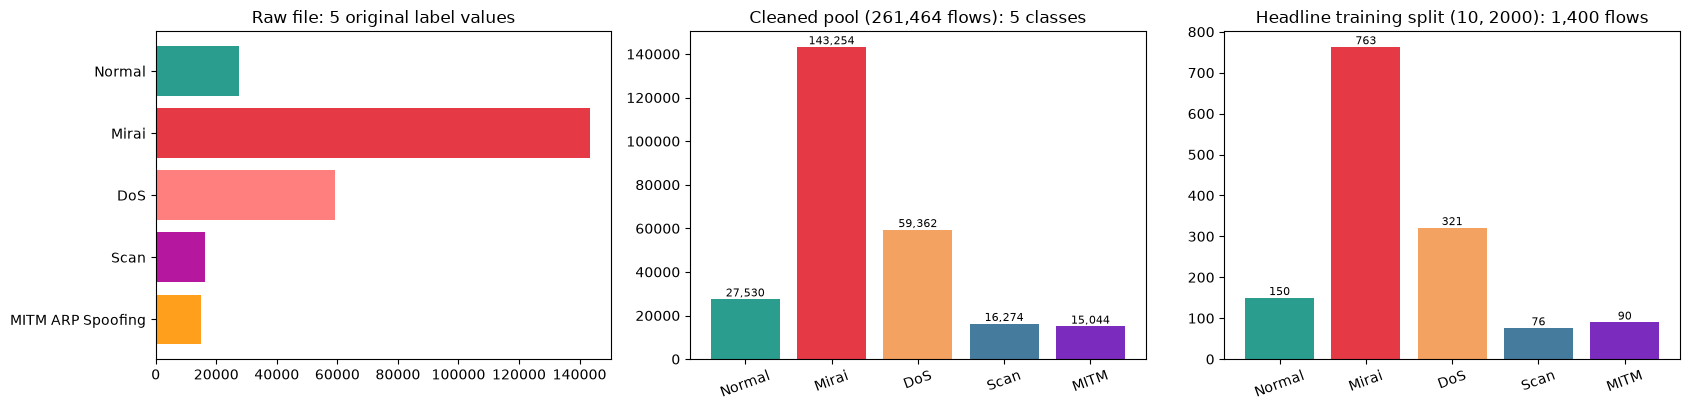

In [8]:
PAL5 = dict(zip(CLASSES, ["#2a9d8f", "#e63946", "#f4a261", "#457b9d", "#7b2cbf"]))
PAL9 = dict(zip(ATTACKS, ["#2a9d8f", "#e63946", "#ff7f7f", "#b5179e", "#ff9f1c", "#f4a261", "#457b9d", "#8ecae6", "#7b2cbf", "#999999"][:len(ATTACKS)]))
MULTI = len(ATTACKS) > len(CLASSES)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
c9 = RAW_ATTACK_COUNTS.reindex(ATTACKS)
ax[0].barh(ATTACKS, c9.values, color=[PAL9[a] for a in ATTACKS]); ax[0].set_title(f"Raw file: {len(ATTACKS)} original label values"); ax[0].invert_yaxis()
c5 = pool["cls"].value_counts().reindex(CLASSES)
ax[1].bar(CLASSES, c5.values, color=[PAL5[c] for c in CLASSES]); ax[1].set_title(f"Cleaned pool ({len(pool):,} flows): 5 classes")
ctr = np.bincount(Dh["ytr"], minlength=5)
ax[2].bar(CLASSES, ctr, color=[PAL5[c] for c in CLASSES]); ax[2].set_title(f"Headline training split {HEADLINE}: {len(Dh['ytr']):,} flows")
for a in ax[1:]:
    for t in a.get_xticklabels(): t.set_rotation(20)
for a, v in zip(ax[1:], (c5.values, ctr)):
    for i, h in enumerate(v): a.text(i, h, f"{h:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

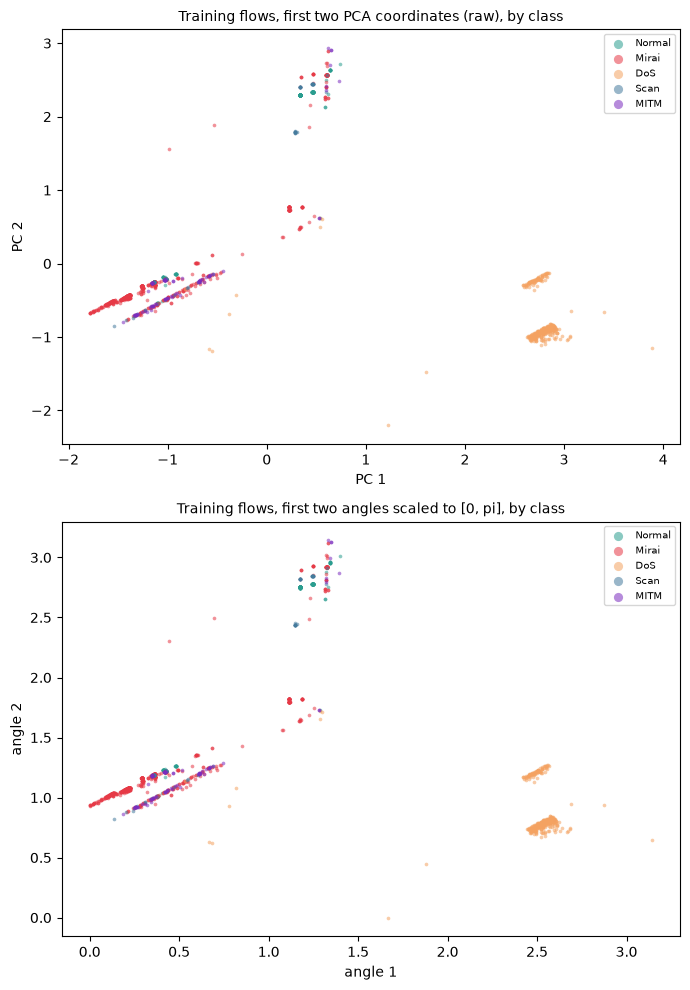

Every point is one real training flow of IoTID20 (1,400 flows); the colours are the ground-truth labels.


In [9]:
def scatter_panel(ax, P, labels, pal, title, xl, yl):
    for lab in pal:
        m = labels == lab
        if m.any(): ax.scatter(P[m, 0], P[m, 1], s=7, alpha=0.55, color=pal[lab], label=lab, linewidths=0)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

cls_tr = np.array(CLASSES)[Dh["ytr"]]
fig, axs = plt.subplots(2, 2 if MULTI else 1, figsize=(13 if MULTI else 7, 10), squeeze=False)
scatter_panel(axs[0, 0], Dh["Ptr"], cls_tr, PAL5, "Training flows, first two PCA coordinates (raw), by class", "PC 1", "PC 2")
scatter_panel(axs[1, 0], Dh["Atr"], cls_tr, PAL5, "Training flows, first two angles scaled to [0, pi], by class", "angle 1", "angle 2")
if MULTI:
    scatter_panel(axs[0, 1], Dh["Ptr"], Dh["atr"], PAL9, "same, by original attack type", "PC 1", "PC 2")
    scatter_panel(axs[1, 1], Dh["Atr"], Dh["atr"], PAL9, "same, by original attack type", "angle 1", "angle 2")
for a in axs.ravel(): a.legend(markerscale=2.5, fontsize=7, loc="best")
plt.tight_layout(); plt.show()
print(f"Every point is one real training flow of IoTID20 ({len(cls_tr):,} flows); the colours are the ground-truth labels.")

## 4. Metrics and the nine classical baselines

The paper's seven metrics: accuracy, weighted precision, weighted recall, weighted F1, macro one-vs-rest specificity, MCC, training time. The nine classical
models use scikit-learn defaults (Random Forest and Gradient Boosting with 100 trees, KNN with $k=5$, three SVMs with `C = 1`) and are trained on **exactly** the PCA angles
the quantum models receive. A Random Forest on all scaled attributes (before selection and PCA) is added as a reference for what the PCA step costs.

In [10]:
def macro_specificity(cm):
    spec = []
    for k in range(cm.shape[0]):
        tn = cm.sum() - cm[k].sum() - cm[:, k].sum() + cm[k, k]; fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp) if (tn + fp) else 1.0)
    return float(np.mean(spec))

def metrics(y_true, y_pred, seconds=np.nan):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    return dict(acc=accuracy_score(y_true, y_pred),
                prec=precision_score(y_true, y_pred, average="weighted", zero_division=0),
                rec=recall_score(y_true, y_pred, average="weighted", zero_division=0),
                f1=f1_score(y_true, y_pred, average="weighted", zero_division=0),
                spec=macro_specificity(cm), mcc=matthews_corrcoef(y_true, y_pred), time=seconds)

def classical_models(seed):
    return {"RandomForest": RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1),
            "KNN": KNeighborsClassifier(n_neighbors=5),
            "GradientBoost": GradientBoostingClassifier(n_estimators=100, random_state=seed),
            "DecisionTree": DecisionTreeClassifier(random_state=seed),
            "SVM RBF": SVC(kernel="rbf", C=SVM_C), "SVM Poly": SVC(kernel="poly", C=SVM_C), "SVM Linear": SVC(kernel="linear", C=SVM_C),
            "LogisticReg": LogisticRegression(max_iter=1000, random_state=seed), "NaiveBayes": GaussianNB()}

def run_classical(D):
    out, preds = {}, {}
    for name, mdl in classical_models(D["seed"]).items():
        t0 = time.perf_counter(); mdl.fit(D["Ptr"], D["ytr"]); p = mdl.predict(D["Pte"]); dt = time.perf_counter() - t0
        out[name] = metrics(D["yte"], p, dt); preds[name] = p
    rf = RandomForestClassifier(n_estimators=100, random_state=D["seed"], n_jobs=-1)       # reference on all attributes
    t0 = time.perf_counter(); rf.fit(D["Ftr"], D["ytr"]); p = rf.predict(D["Fte"])
    out["RandomForest (all features)"] = metrics(D["yte"], p, time.perf_counter() - t0); preds["RandomForest (all features)"] = p
    return out, preds

_t = time.perf_counter(); _c, _ = run_classical(Dh)
print(f"classical baselines on the headline configuration {HEADLINE} ({time.perf_counter()-_t:.0f} s):")
display(pd.DataFrame(_c).T.round(4))

classical baselines on the headline configuration (10, 2000) (18 s):


,acc,prec,rec,f1,spec,mcc,time
RandomForest,0.9233,0.9186,0.9233,0.9188,0.9723,0.8771,1.2965
KNN,0.8850,0.8806,0.8850,0.8817,0.9614,0.8160,0.0594
GradientBoost,0.9083,0.9022,0.9083,0.9022,0.9661,0.8525,13.8217
DecisionTree,0.8967,0.8962,0.8967,0.8959,0.9677,0.8367,0.0637
SVM RBF,0.8417,0.7455,0.8417,0.7892,0.9369,0.7434,0.5416
SVM Poly,0.8433,0.7474,0.8433,0.7911,0.9380,0.7464,0.1876
SVM Linear,0.8083,0.7265,0.8083,0.7627,0.9316,0.6891,0.1881
LogisticReg,0.8217,0.7331,0.8217,0.7731,0.9338,0.7097,0.1652
NaiveBayes,0.7300,0.8302,0.7300,0.7640,0.9373,0.6319,0.0149
RandomForest (all features),0.8617,0.8378,0.8617,0.8459,0.9501,0.7752,0.9076


## 5. The quantum feature maps and the exact fidelity kernel

With one repetition every map is *diagonal in the computational basis after the Hadamards*:
$|\psi(x)\rangle = 2^{-n/2}\sum_{z\in\{0,1\}^n} e^{i f_x(z)}|z\rangle$ with

* **Z map**: $f_x(z)=\sum_i 2x_i z_i$ (a product state, so $K(x,y)=\prod_i\cos^2(x_i-y_i)$ in closed form);
* **ZZ map** (and the **Pauli map** with `paulis=["Z","ZZ"]`, which Qiskit builds identically): $f_x(z)=\sum_i 2x_i z_i+\sum_{i<j}2(\pi-x_i)(\pi-x_j)(z_i\oplus z_j)$.

So the fidelity kernel is $K=|S S^\dagger|^2$ for the matrix $S$ of these states, which a matrix product evaluates for thousands of flows in seconds to minutes. The cell below
implements it in blocks (so 16 qubits, 65,536 amplitudes per state, fit in memory) and **checks every map against Qiskit's `Statevector` of the real feature-map circuit**, including
the claim of the paper that the Pauli and ZZ maps give identical states.

In [11]:
class FidelityKernel:
    """Exact |<psi(a)|psi(b)>|^2 for the Z map (closed form) or the ZZ/Pauli map (phase-state matrix product)."""
    def __init__(self, n, kind):
        assert kind in ("z", "zz")
        self.n, self.kind, self.D = n, kind, 2 ** n
        if kind == "zz":
            idx = np.arange(self.D)
            self.B = ((idx[:, None] >> np.arange(n)) & 1).astype(np.float64)               # bit i of the basis index = qubit i
            self.pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]               # ENTANGLEMENT = "full"
            self.C = np.stack([(self.B[:, i].astype(np.uint8) ^ self.B[:, j].astype(np.uint8)) for i, j in self.pairs], 1).astype(np.float64)

    def states(self, X):
        """Rows are the statevectors (complex64). The phase is reduced mod 2 pi in float64 before the float32 cast."""
        X = np.asarray(X, float)
        f = 2.0 * X @ self.B.T
        phi = np.stack([(np.pi - X[:, i]) * (np.pi - X[:, j]) for i, j in self.pairs], 1)
        f += 2.0 * phi @ self.C.T
        f = np.mod(f, 2 * np.pi).astype(np.float32)
        return ((np.cos(f) + 1j * np.sin(f)) / np.sqrt(self.D)).astype(np.complex64)

    def gram(self, A, B=None):
        sym = B is None or B is A
        B = A if sym else B
        if self.kind == "z":
            out = np.ones((len(A), len(B)))
            for r in range(0, len(A), 1024):
                blk = np.ones((len(A[r:r + 1024]), len(B)))
                for i in range(self.n):
                    blk *= np.cos(A[r:r + 1024, i][:, None] - B[None, :, i]) ** 2
                out[r:r + 1024] = blk
            return out
        blk = max(16, min(4096, (1 << 23) // self.D))
        cache = len(B) * self.D * 8 <= 2.0e9                      # keep all states of B in memory (complex64) when they fit in 2 GB, otherwise regenerate them per block pair
        SB = [self.states(B[j:j + blk]) for j in range(0, len(B), blk)] if cache else None
        out = np.empty((len(A), len(B)))
        for i in range(0, len(A), blk):
            Si = (SB[i // blk] if (sym and cache) else self.states(A[i:i + blk])).conj()
            for j in range(i if sym else 0, len(B), blk):
                Sj = SB[j // blk] if cache else (Si.conj() if (sym and j == i) else self.states(B[j:j + blk]))
                G = np.abs(Si @ Sj.T) ** 2
                out[i:i + blk, j:j + blk] = G
                if sym and j != i:
                    out[j:j + blk, i:i + blk] = G.T
        return out

def qiskit_feature_map(kind, n):
    if kind == "z":
        return z_feature_map(n, reps=FEATURE_MAP_REPS)
    if kind == "zz":
        return zz_feature_map(n, reps=FEATURE_MAP_REPS, entanglement=ENTANGLEMENT)
    return pauli_feature_map(n, reps=FEATURE_MAP_REPS, paulis=["Z", "ZZ"], entanglement=ENTANGLEMENT)      # "pauli"

def qiskit_state(fm, x):
    return Statevector(fm.assign_parameters(dict(zip(fm.parameters, x)))).data

# --- verification against Qiskit's Statevector for the headline qubit count ---
nv = HEADLINE[0]; Xv = Dh["Ptr"][:8]
names = [p.name for p in z_feature_map(nv, reps=1).parameters]
assert names == [f"x[{i}]" for i in range(nv)], names           # parameter order = feature order
rows = []
for kind in ("z", "zz", "pauli"):
    fm = qiskit_feature_map(kind, nv); fk = FidelityKernel(nv, "z" if kind == "z" else "zz")
    S_q = np.array([qiskit_state(fm, x) for x in Xv])
    K_q = np.abs(S_q.conj() @ S_q.T) ** 2
    K_f = fk.gram(Xv)
    rows.append((kind, np.abs(K_q - K_f).max()))
    assert np.allclose(K_q, K_f, atol=1e-5), kind
if nv <= 12:                                              # closed-form Z kernel vs the Statevector overlaps
    Sz = np.array([qiskit_state(z_feature_map(nv, reps=1), x) for x in Xv])
    assert np.allclose(FidelityKernel(nv, "z").gram(Xv), np.abs(Sz.conj() @ Sz.T) ** 2, atol=1e-6)
pq = np.array([qiskit_state(qiskit_feature_map("pauli", nv), x) for x in Xv]); zq = np.array([qiskit_state(qiskit_feature_map("zz", nv), x) for x in Xv])
print("max |Gram(fast) - Gram(Qiskit Statevector)| per map:", {k: float(f"{v:.1e}") for k, v in rows})
print("Pauli(['Z','ZZ']) and ZZ statevectors identical up to phase:", np.allclose(np.abs(np.sum(pq.conj() * zq, 1)), 1.0, atol=1e-6))
print("ZZ circuit parameters:", len(qiskit_feature_map("zz", nv).parameters), "| ZZ-map pairs (full entanglement):", nv * (nv - 1) // 2)

max |Gram(fast) - Gram(Qiskit Statevector)| per map: {'z': 3.6e-15, 'zz': 1.2e-07, 'pauli': 1.2e-07}
Pauli(['Z','ZZ']) and ZZ statevectors identical up to phase: True
ZZ circuit parameters: 10 | ZZ-map pairs (full entanglement): 45


## 6. Quantum Circuit Architecture

All gate-based models of the paper are drawn below from the very Qiskit circuit objects that the notebook executes: the three feature maps used by the kernels (and hence by
QSVC, QVE, QWE, QRF and Pegasos), the fidelity-test circuit $U^\dagger(y)U(x)$ whose all-zero probability is the kernel value, the VQC / SamplerQNN circuit (Z feature map + `RealAmplitudes`
ansatz + measurement) and the EstimatorQNN circuit with its five observables. QVE and QWE need no circuit of their own: they are a classical vote over the predictions of two kernel machines.
QRF uses the Z-map circuit of Qiskit on $\lfloor\sqrt n\rfloor$ qubits. Assumptions where the paper is silent: one repetition of each feature map, full entanglement for ZZ/Pauli,
Z feature map in front of the variational ansatz, `RealAmplitudes` with `reps=2`, `entanglement="full"` (as stated), ansatz parameters initialised by Qiskit-ML's default random initial point.

Z feature map                      qubits=10 depth=   2 (H/P/RY/CX) parameters= 10 trainable=  0 gates={'h': 10, 'p': 10}
ZZ feature map                     qubits=10 depth=  53 (H/P/RY/CX) parameters= 10 trainable=  0 gates={'cx': 90, 'p': 55, 'h': 10}
Pauli(['Z','ZZ']) feature map      qubits=10 depth=  53 (H/P/RY/CX) parameters= 10 trainable=  0 gates={'cx': 90, 'p': 55, 'h': 10}
RealAmplitudes(reps=2, full)       qubits=10 depth=  30 (H/P/RY/CX) parameters= 30 trainable= 30 gates={'cx': 90, 'ry': 30}
VQC / QNN circuit (Z map + ansatz) qubits=10 depth=  32 (H/P/RY/CX) parameters= 40 trainable= 30 gates={'cx': 90, 'ry': 30, 'h': 10, 'p': 10}
QRF member (Z map on floor(sqrt n)=3) qubits= 3 depth=   2 (H/P/RY/CX) parameters=  3 trainable=  0 gates={'h': 3, 'p': 3}


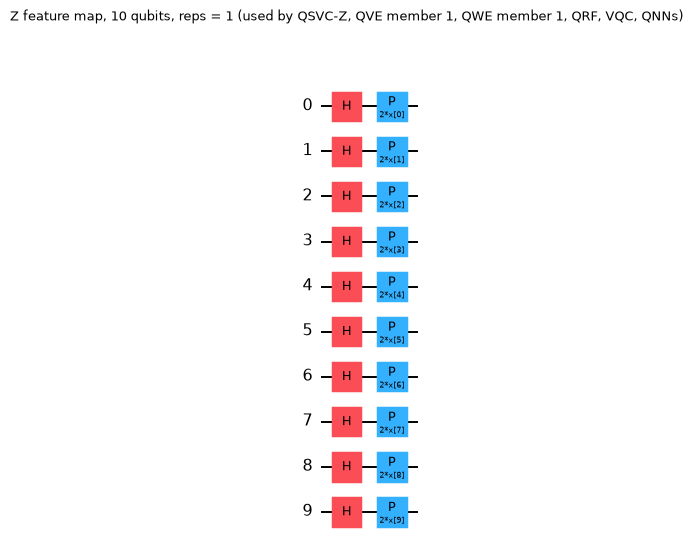

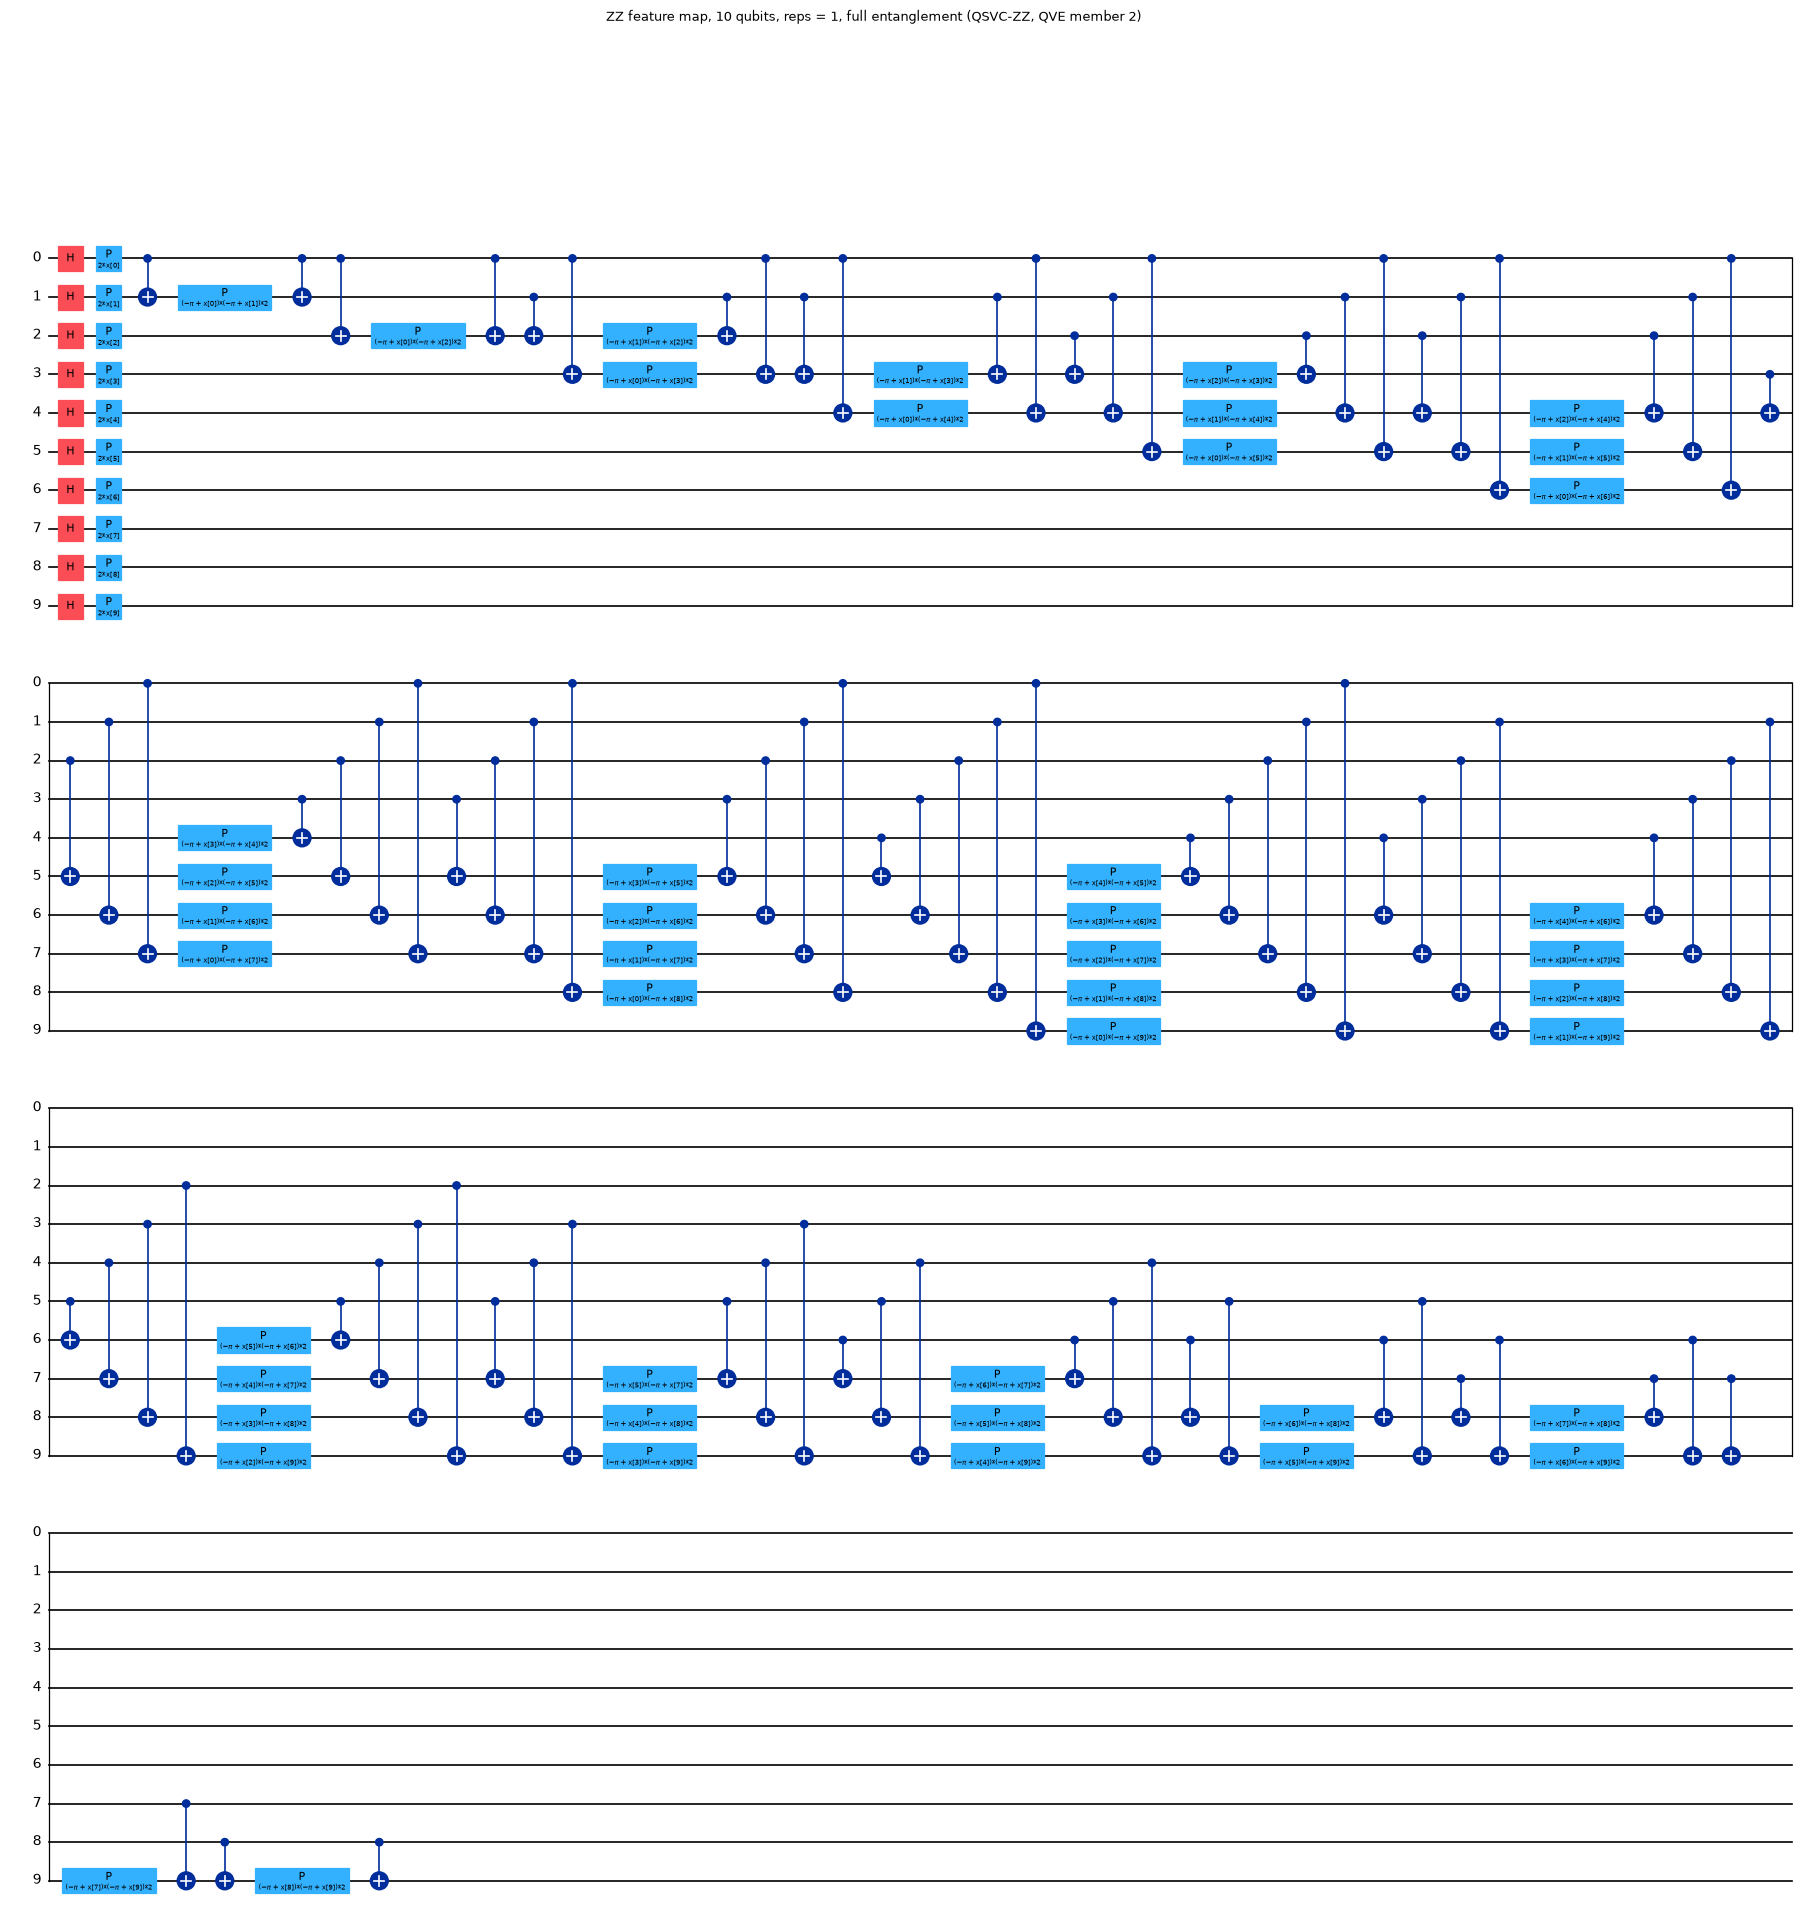

In [12]:
NQ = HEADLINE[0]
from qiskit import transpile
T = lambda c: transpile(c, basis_gates=["h", "p", "ry", "cx"], optimization_level=0)     # the gates that are executed: H, P (phase), RY, CNOT
def stats(name, circ, n_trainable=None):
    d = T(circ)
    ops = dict(d.count_ops())
    print(f"{name:34s} qubits={circ.num_qubits:2d} depth={d.depth():4d} (H/P/RY/CX) parameters={circ.num_parameters:3d} "
          f"trainable={n_trainable if n_trainable is not None else 0:3d} gates={ops}")

fm_z, fm_zz, fm_p = (qiskit_feature_map(k, NQ) for k in ("z", "zz", "pauli"))
ansatz = real_amplitudes(NQ, reps=2, entanglement="full")
vqc_circ = fm_z.compose(ansatz)
for name, c in [("Z feature map", fm_z), ("ZZ feature map", fm_zz), ("Pauli(['Z','ZZ']) feature map", fm_p)]:
    stats(name, c)
stats("RealAmplitudes(reps=2, full)", ansatz, ansatz.num_parameters)
stats("VQC / QNN circuit (Z map + ansatz)", vqc_circ, ansatz.num_parameters)
nrf = int(math.floor(math.sqrt(NQ)))
stats(f"QRF member (Z map on floor(sqrt n)={nrf})", z_feature_map(nrf, reps=1))
for n16 in ([16] if not FAST_MODE else []):
    stats("ZZ feature map (16 qubits)", qiskit_feature_map("zz", n16)); stats("Z feature map (16 qubits)", qiskit_feature_map("z", n16))
    stats("VQC circuit (16 qubits)", z_feature_map(16, reps=1).compose(real_amplitudes(16, reps=2, entanglement="full")), real_amplitudes(16, reps=2, entanglement="full").num_parameters)

fig = T(fm_z).draw("mpl", fold=30, scale=0.7); fig.suptitle(f"Z feature map, {NQ} qubits, reps = 1 (used by QSVC-Z, QVE member 1, QWE member 1, QRF, VQC, QNNs)", fontsize=9); display(fig)
fig = T(fm_zz).draw("mpl", fold=45, scale=0.6); fig.suptitle(f"ZZ feature map, {NQ} qubits, reps = 1, full entanglement (QSVC-ZZ, QVE member 2)", fontsize=9); display(fig)

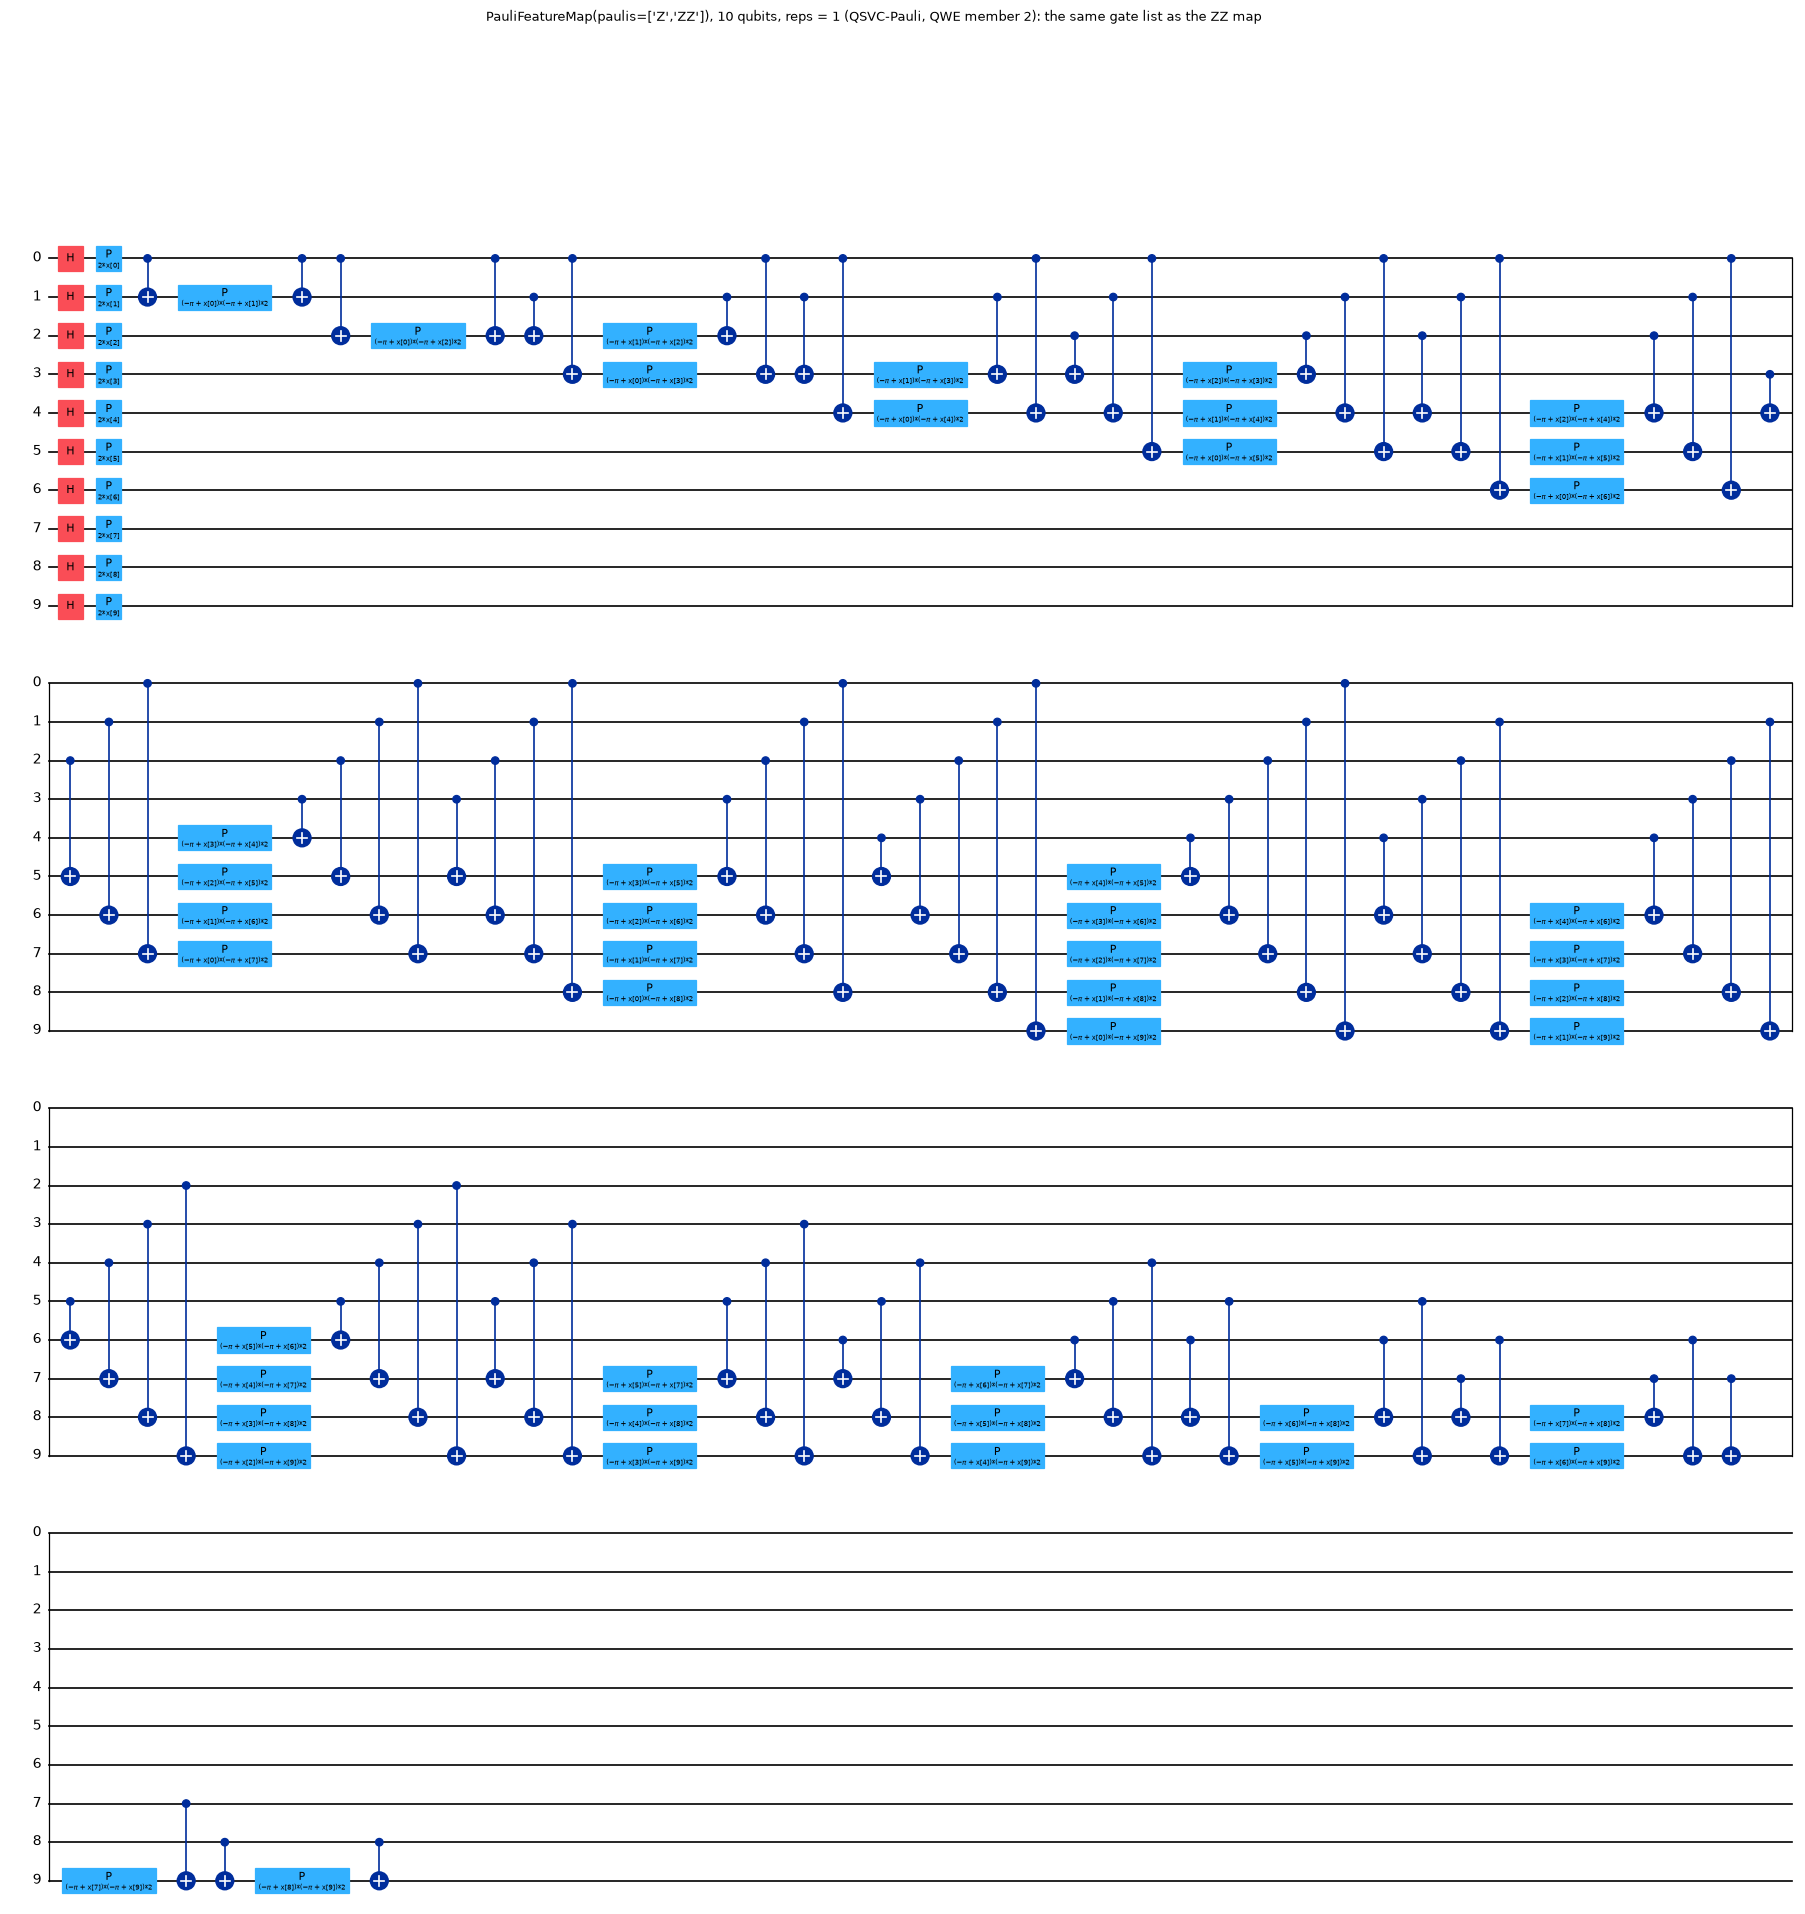

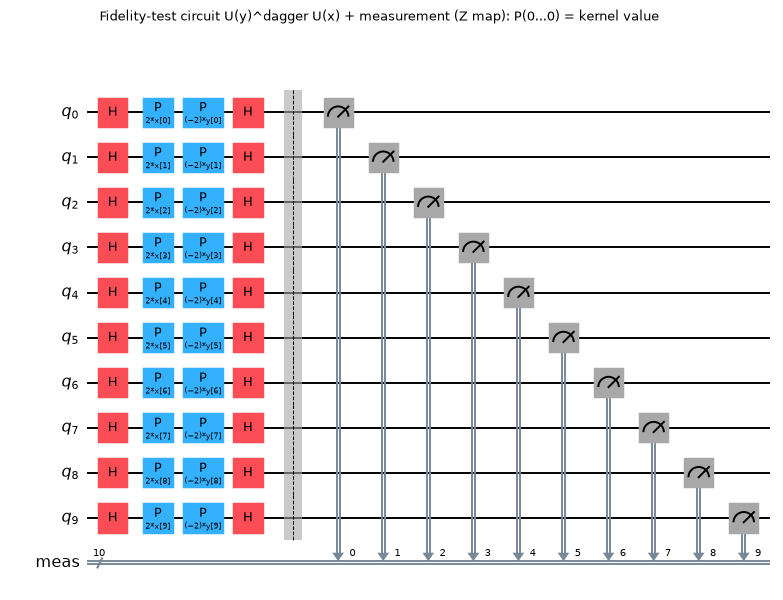

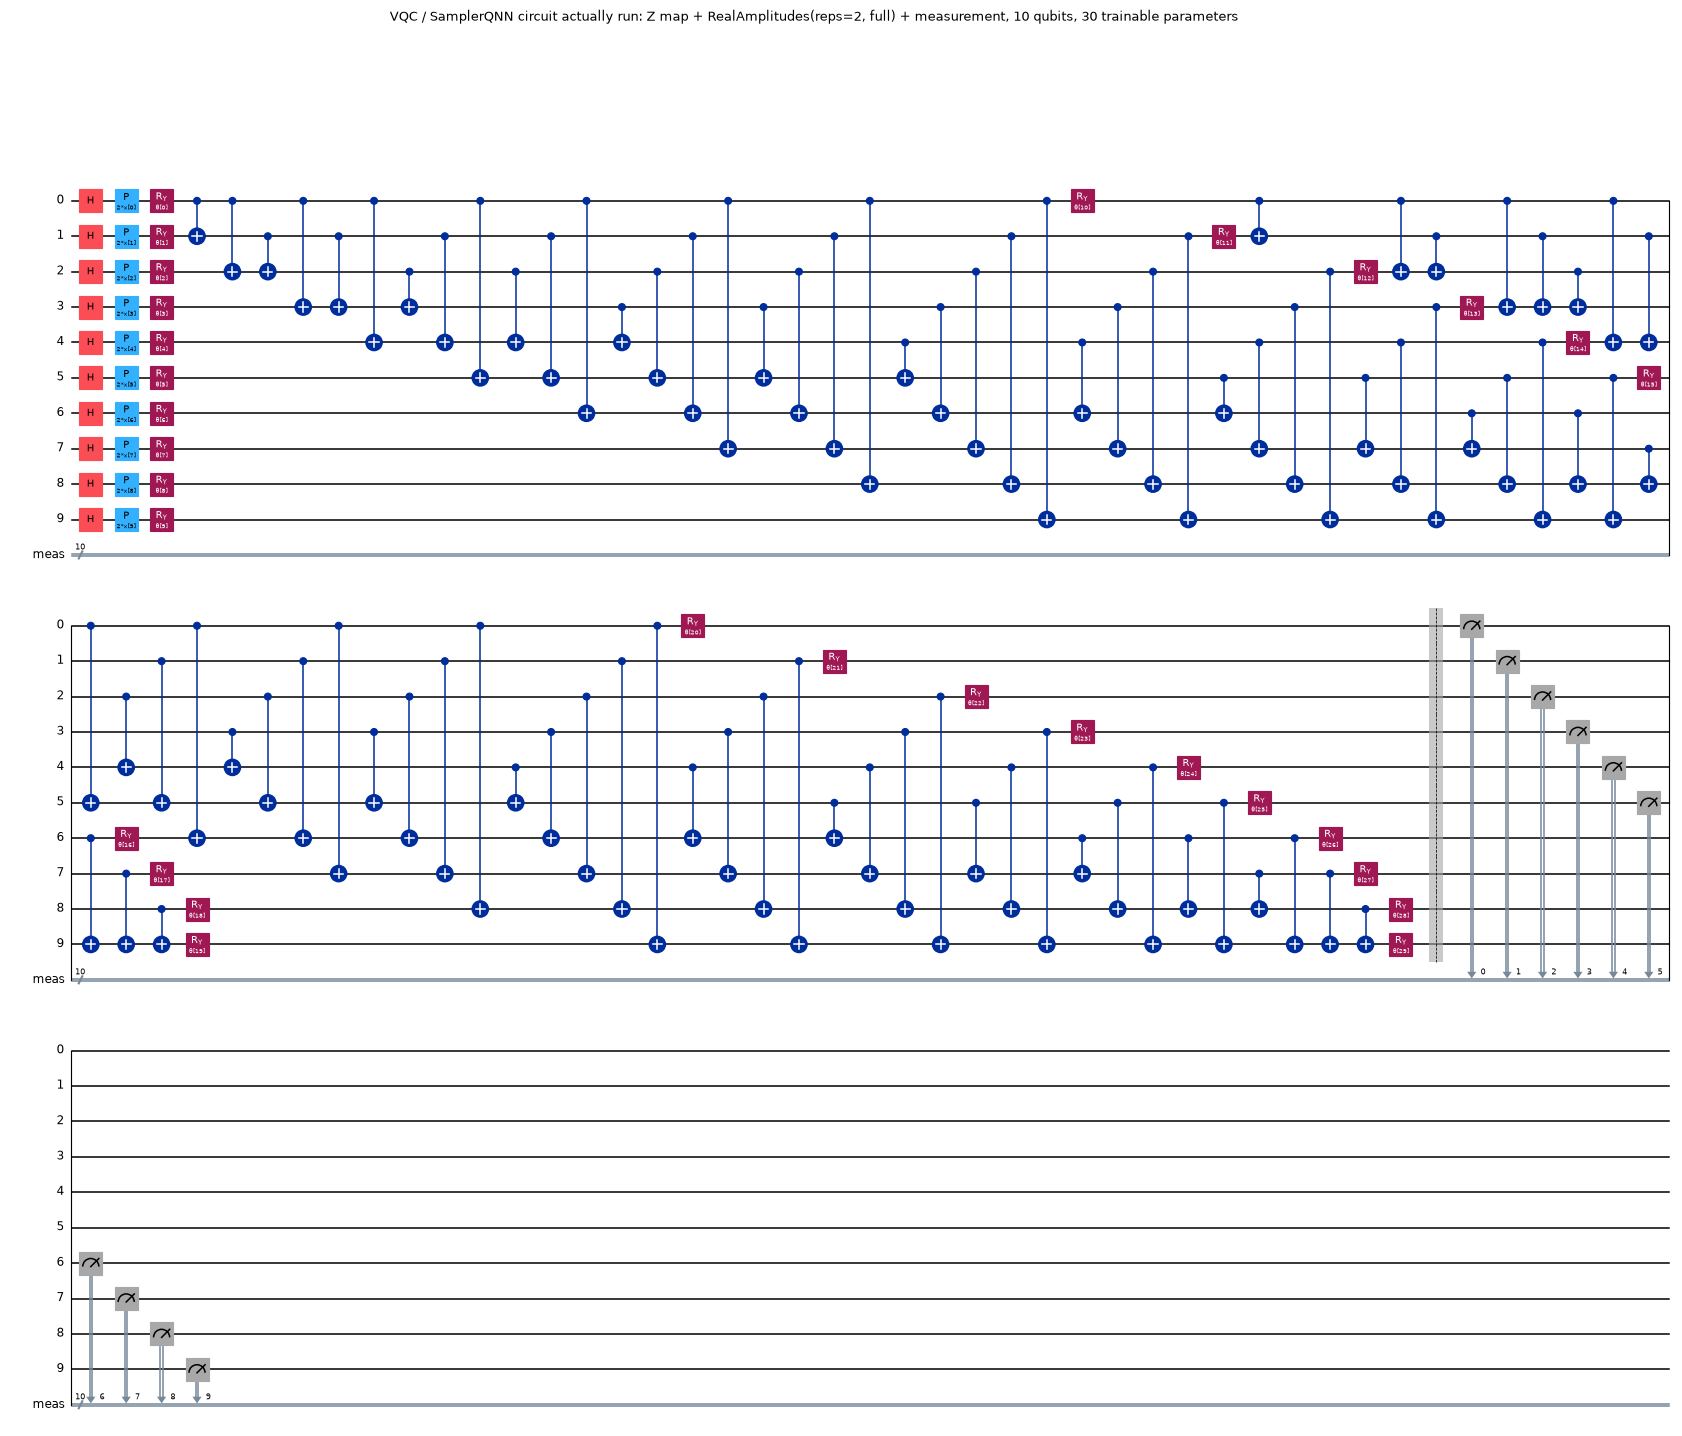

EstimatorQNN runs the same circuit (without measurement) and returns the five expectation values: ['IIIIIIIIIZ', 'IIIIIIIIZI', 'IIIIIIIZII', 'IIIIIIZIII', 'IIIIIZIIII']
QVE / QWE / QRF: no extra circuit; QVE = 2 kernel machines (Z and ZZ circuits above), QWE = Z and Pauli circuits, QRF = 3 Z circuits on 3 qubits


In [13]:
fig = T(fm_p).draw("mpl", fold=45, scale=0.6); fig.suptitle(f"PauliFeatureMap(paulis=['Z','ZZ']), {NQ} qubits, reps = 1 (QSVC-Pauli, QWE member 2): the same gate list as the ZZ map", fontsize=9); display(fig)
from qiskit import QuantumCircuit
k_demo = QuantumCircuit(NQ)
a_par = z_feature_map(NQ, reps=1, parameter_prefix="x"); b_par = z_feature_map(NQ, reps=1, parameter_prefix="y")
k_demo.compose(a_par, inplace=True); k_demo.compose(b_par.inverse(), inplace=True); k_demo.measure_all()
fig = T(k_demo).draw("mpl", fold=30, scale=0.7); fig.suptitle("Fidelity-test circuit U(y)^dagger U(x) + measurement (Z map): P(0...0) = kernel value", fontsize=9); display(fig)
vqc_exec = vqc_circ.copy(); vqc_exec.measure_all()
fig = T(vqc_exec).draw("mpl", fold=45, scale=0.55); fig.suptitle(f"VQC / SamplerQNN circuit actually run: Z map + RealAmplitudes(reps=2, full) + measurement, {NQ} qubits, {ansatz.num_parameters} trainable parameters", fontsize=9); display(fig)
obs = [SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], num_qubits=NQ) for k in range(5)]
print("EstimatorQNN runs the same circuit (without measurement) and returns the five expectation values:", [str(o.paulis[0]) for o in obs])
print("QVE / QWE / QRF: no extra circuit; QVE = 2 kernel machines (Z and ZZ circuits above), QWE = Z and Pauli circuits, QRF = 3 Z circuits on", nrf, "qubits")

## 7. The quantum ensembles, QRF, the QSVC variants and Pegasos

For one configuration the notebook computes the Z and ZZ kernel matrices once (training x training and test x training) and then:

* **QSVC-Z, QSVC-ZZ, QSVC-Pauli (precomputed)**: `SVC(kernel="precomputed", C=1)`. (The Pauli kernel is the ZZ kernel; the check in Section 5 proves the circuits equal.)
* **QVE** (Eq. 1): hard vote of QSVC-Z and QSVC-ZZ; ties go to the lower-index member (Z).
* **QWE** (Eq. 2-3): stratified 80/20 split of the training data; Z and Pauli QSVCs fitted on the 80 %, weights proportional to their validation accuracy; weighted vote.
* **QRF** (Eq. 4): 3 Z-map QSVCs on bootstrap samples with $\lfloor\sqrt n\rfloor$ random features, plurality vote.
* **QSVC Pegasos**: `PegasosQSVC(precomputed=True)` one-vs-rest on the Z kernel (the Qiskit class only handles two classes).

The time reported for a quantum model includes the (shared) kernel computation. It is CPU time of an exact vectorised simulation and is not comparable with the paper's GPU times.

In [14]:
def priority_vote(preds, weights=None):
    """Weighted plurality vote. Ties are resolved in favour of the class predicted by the lowest-index member (paper, Sec. II-B)."""
    P = np.stack(preds, 1); w = np.ones(P.shape[1]) if weights is None else np.asarray(weights, float)
    out = np.empty(len(P), int)
    for r, row in enumerate(P):
        score = {}
        for m, c in enumerate(row):
            score[c] = score.get(c, 0.0) + w[m]
        best = max(score.values())
        out[r] = next(c for m, c in enumerate(row) if score[c] >= best - 1e-12)
    return out

def svc_pre(Ktr, ytr, Kte):
    clf = SVC(kernel="precomputed", C=SVM_C).fit(Ktr, ytr)
    return clf.predict(Kte)

def pegasos_ovr(Ktr, ytr, Kte, seed):
    scores = []
    for k in range(len(CLASSES)):
        algorithm_globals.random_seed = seed + k
        peg = PegasosQSVC(precomputed=True, C=PEGASOS_C, num_steps=PEGASOS_STEPS)
        yk = (ytr == k).astype(int)
        peg.fit(Ktr, yk)
        scores.append(-peg.decision_function(Kte))     # PegasosQSVC treats the smaller label (0 = "rest") as positive, so -score = evidence for class k
    return np.argmax(np.stack(scores, 1), 1)

def run_quantum(D, pegasos=True):
    n, seed = D["n"], D["seed"]; ytr, yte = D["ytr"], D["yte"]
    res, preds, extra = {}, {}, {}
    K = {}
    for kind in ("z", "zz"):
        t0 = time.perf_counter(); fk = FidelityKernel(n, kind)
        Ktr = fk.gram(D["Ptr"]); Kte = fk.gram(D["Pte"], D["Ptr"])
        K[kind] = (Ktr, Kte, time.perf_counter() - t0)
    tk = {k: v[2] for k, v in K.items()}
    # --- single QSVCs ---
    for name, kind in (("QSVC Z", "z"), ("QSVC ZZ", "zz"), ("QSVC Pauli", "zz")):
        t0 = time.perf_counter(); p = svc_pre(K[kind][0], ytr, K[kind][1]); dt = time.perf_counter() - t0 + tk[kind]
        res[name] = metrics(yte, p, dt); preds[name] = p
    # --- QVE: full training split, fixed priority Z > ZZ ---
    p = priority_vote([preds["QSVC Z"], preds["QSVC ZZ"]])
    res["QVE"] = metrics(yte, p, res["QSVC Z"]["time"] + res["QSVC ZZ"]["time"]); preds["QVE"] = p
    extra["QVE_equals_QSVC_Z"] = bool(np.array_equal(p, preds["QSVC Z"]))
    # --- QWE: 80/20 internal split, weights from validation accuracy ---
    i_tr, i_val = train_test_split(np.arange(len(ytr)), test_size=0.20, stratify=ytr, random_state=seed)
    t0 = time.perf_counter(); vals, tp = [], []
    for kind in ("z", "zz"):                                     # member 1: Z map, member 2: Pauli map (== ZZ kernel)
        Ktr, Kte, _ = K[kind]
        clf = SVC(kernel="precomputed", C=SVM_C).fit(Ktr[np.ix_(i_tr, i_tr)], ytr[i_tr])
        vals.append(accuracy_score(ytr[i_val], clf.predict(Ktr[np.ix_(i_val, i_tr)]))); tp.append(clf.predict(Kte[:, i_tr]))
    w = np.array(vals) / np.sum(vals)
    p = priority_vote(tp, w)
    res["QWE"] = metrics(yte, p, time.perf_counter() - t0 + tk["z"] + tk["zz"]); preds["QWE"] = p
    extra["QWE_weights"] = w.round(4).tolist(); extra["QWE_val_acc"] = np.round(vals, 4).tolist()
    # --- QRF: 3 x QSVC-Z on bootstrap samples with floor(sqrt n) random features ---
    r = np.random.default_rng(seed); nf = int(math.floor(math.sqrt(n))); votes = []; t0 = time.perf_counter()
    for e in range(QRF_ESTIMATORS):
        bi = r.integers(0, len(ytr), len(ytr)); fi = np.sort(r.choice(n, nf, replace=False)); fk = FidelityKernel(nf, "z")
        Ktr = fk.gram(D["Ptr"][bi][:, fi]); Kte = fk.gram(D["Pte"][:, fi], D["Ptr"][bi][:, fi])
        votes.append(svc_pre(Ktr, ytr[bi], Kte))
    V = np.stack(votes, 1); p = np.array([np.bincount(row, minlength=len(CLASSES)).argmax() for row in V])
    res["QRF"] = metrics(yte, p, time.perf_counter() - t0); preds["QRF"] = p
    # --- Pegasos (one-vs-rest on the Z kernel) ---
    if pegasos:
        t0 = time.perf_counter(); p = pegasos_ovr(K["z"][0], ytr, K["z"][1], seed)
        res["QSVC Pegasos"] = metrics(yte, p, time.perf_counter() - t0 + tk["z"]); preds["QSVC Pegasos"] = p
    extra["kernel_seconds"] = {k: round(v, 1) for k, v in tk.items()}
    extra["mean_offdiag_kernel"] = {k: float((K[k][0].sum() - np.trace(K[k][0])) / (K[k][0].size - len(K[k][0]))) for k in K}
    return res, preds, extra, K

_t = time.perf_counter(); _r, _p, _e, _K = run_quantum(Dh)
print(f"quantum models on the headline configuration {HEADLINE} ({time.perf_counter()-_t:.0f} s)")
print("QVE predictions identical to QSVC-Z predictions:", _e["QVE_equals_QSVC_Z"], "| QWE validation accuracies:", _e["QWE_val_acc"], "-> weights", _e["QWE_weights"])
print("mean off-diagonal kernel value (Z, ZZ):", {k: round(v, 5) for k, v in _e["mean_offdiag_kernel"].items()}, "| kernel seconds:", _e["kernel_seconds"])
display(pd.DataFrame(_r).T.round(4))
del _K

quantum models on the headline configuration (10, 2000) (37 s)
QVE predictions identical to QSVC-Z predictions: True | QWE validation accuracies: [0.8357, 0.8893] -> weights [0.4845, 0.5155]
mean off-diagonal kernel value (Z, ZZ): {'z': 0.25778, 'zz': 0.03374} | kernel seconds: {'z': 2.1, 'zz': 1.1}


,acc,prec,rec,f1,spec,mcc,time
QSVC Z,0.8383,0.7981,0.8383,0.7908,0.9350,0.7376,2.2599
QSVC ZZ,0.8967,0.8916,0.8967,0.8908,0.9621,0.8337,1.3594
QSVC Pauli,0.8967,0.8916,0.8967,0.8908,0.9621,0.8337,1.5987
QVE,0.8383,0.7981,0.8383,0.7908,0.9350,0.7376,3.6193
QWE,0.8950,0.8903,0.8950,0.8892,0.9614,0.8310,3.8261
QRF,0.7717,0.6887,0.7717,0.7088,0.9045,0.6219,2.4016
QSVC Pegasos,0.7050,0.5447,0.7050,0.6145,0.8906,0.4928,31.0712


### 7.1 Do the three QSVC interfaces agree? (Standard, Precomputed, Callable)

The paper finds the Standard, Precomputed and Callable QSVC implementations of one feature map practically identical and concludes that the encoding, not the software
interface, drives accuracy. Here the same is tested on a small subset where Qiskit's own `QSVC` with `FidelityStatevectorKernel` is affordable: (a) `QSVC(quantum_kernel=FidelityStatevectorKernel(...))`
(Standard), (b) `SVC(kernel="precomputed")` on our fast Gram matrix (Precomputed), (c) `SVC(kernel=callable)` where the callable returns our fast Gram matrix (Callable). The Gram matrices
and the predictions must agree.

In [15]:
def implementation_check(D, n_check=CHECK_N):
    n = D["n"]; rs = np.random.default_rng(SEED)
    itr = np.sort(rs.choice(len(D["ytr"]), n_check, replace=False)); ite = np.sort(rs.choice(len(D["yte"]), n_check, replace=False))
    Xa, ya, Xb, yb = D["Ptr"][itr], D["ytr"][itr], D["Pte"][ite], D["yte"][ite]
    rows = []
    for kind in ("z", "zz", "pauli"):
        fm = qiskit_feature_map(kind, n); fk = FidelityKernel(n, "z" if kind == "z" else "zz")
        t0 = time.perf_counter()
        qk = FidelityStatevectorKernel(feature_map=fm)
        std = QSVC(quantum_kernel=qk, C=SVM_C).fit(Xa, ya); p_std = std.predict(Xb); t_std = time.perf_counter() - t0
        K_std = qk.evaluate(Xa, Xa); K_fast = fk.gram(Xa)
        p_pre = svc_pre(K_fast, ya, fk.gram(Xb, Xa))
        p_call = SVC(kernel=lambda A, B: fk.gram(np.asarray(A), np.asarray(B)), C=SVM_C).fit(Xa, ya).predict(Xb)
        rows.append(dict(map=kind, gram_max_abs_diff=float(np.abs(K_std - K_fast).max()), gram_allclose=bool(np.allclose(K_std, K_fast, atol=1e-5)),
                         pred_std_eq_pre=bool(np.array_equal(p_std, p_pre)), pred_pre_eq_call=bool(np.array_equal(p_pre, p_call)),
                         acc_standard=accuracy_score(yb, p_std), acc_precomputed=accuracy_score(yb, p_pre), acc_callable=accuracy_score(yb, p_call),
                         qiskit_QSVC_seconds=round(t_std, 1)))
    return pd.DataFrame(rows)

IMPL = implementation_check(Dh)
print(f"{CHECK_N} training flows and {CHECK_N} test flows of the headline configuration {HEADLINE}")
display(IMPL.round(4))

100 training flows and 100 test flows of the headline configuration (10, 2000)


,map,gram_max_abs_diff,gram_allclose,pred_std_eq_pre,pred_pre_eq_call,acc_standard,acc_precomputed,acc_callable,qiskit_QSVC_seconds
0,z,0.0,True,True,True,0.79,0.79,0.79,2.9
1,zz,0.0,True,True,True,0.82,0.82,0.82,16.2
2,pauli,0.0,True,True,True,0.82,0.82,0.82,13.9


## 8. Variational models: VQC (COBYLA, SPSA, Adam), EstimatorQNN, SamplerQNN

These are the paper's five trainable baselines (Z feature map, then `RealAmplitudes(reps=2, entanglement="full")`). Their cost is the reason for the paper's multi-day GPU times: every optimiser
step evaluates the circuit for every training flow through Qiskit's primitives (about 0.5 s per flow and step on a CPU here), and Adam also needs parameter-shift gradients (2 x 30 shifted circuits per flow and step).

To make them affordable the notebook uses a **batched exact statevector simulator built from the very gate list of the Qiskit circuit** (the `ry` and `cx` gates of the decomposed ansatz after the Z-map product state),
plus the optimisers of `qiskit_machine_learning.optimizers` (COBYLA, SPSA, ADAM) and Qiskit-ML's own loss definitions. Section 8.1 proves that the simulator reproduces (i) the exact `Statevector` of the Qiskit circuit and
(ii) the forward pass of the real Qiskit-ML `SamplerQNN` (the network `VQC` wraps, with the same `x % 5` read-out) and `EstimatorQNN` objects. Shot noise is emulated as a multinomial draw (1,024 shots for VQC as with `StatevectorSampler`'s default, 2,048 for SamplerQNN as in the paper), gradients for Adam are the
exact parameter-shift rule. `EstimatorQNN` uses the five observables $Z_0,\dots,Z_4$ with a squared-error loss against the one-hot label (its outputs lie in $[-1, 1]$, so a cross-entropy would be undefined).

The training sets are still small (`VAR_BUDGET`; the variational models are run for the 10-qubit configurations only, because a 16-qubit forward pass is about 100 times slower on a CPU) and a Random Forest, an RBF-SVM and the Z-kernel QSVC are trained on exactly the same flows as a fair reference.
The numbers show the *trend* of trainable circuits at a matched small data budget, not the paper's exact accuracies.

In [16]:
from qiskit.circuit import QuantumCircuit

class BatchedAnsatzSim:
    """Exact batched statevector simulator for an `ry`/`cx` ansatz taken from a Qiskit circuit (little-endian: qubit q = bit q of the basis index)."""
    def __init__(self, ansatz):
        c = ansatz
        for _ in range(10):
            if all(i.operation.name in ("ry", "cx") for i in c.data):
                break
            c = c.decompose()
        assert all(i.operation.name in ("ry", "cx") for i in c.data), "unsupported gate in the ansatz"
        self.n, self.D, self.m = c.num_qubits, 2 ** c.num_qubits, c.num_parameters
        pidx = {p: i for i, p in enumerate(ansatz.parameters)}
        ops = []
        for inst in c.data:
            q = [c.find_bit(b).index for b in inst.qubits]
            if inst.operation.name == "ry":
                ops.append(("ry", q[0], pidx[list(inst.operation.params[0].parameters)[0]]))
            else:
                ops.append(("cx", q[0], q[1]))
        # merge each run of consecutive CX gates into one gather permutation
        self.ops, run = [], []
        idx = np.arange(self.D)
        def flush():
            if run:
                v = idx.copy()
                for ctl, tgt in reversed(run):
                    v = v ^ (((v >> ctl) & 1) << tgt)
                self.ops.append(("perm", v)); run.clear()
        for op in ops:
            if op[0] == "cx":
                run.append((op[1], op[2]))
            else:
                flush(); self.ops.append(op)
        flush()
        bits = (idx[:, None] >> np.arange(self.n)) & 1
        self.class_matrix = np.zeros((self.D, len(CLASSES)), np.float32); self.class_matrix[idx, idx % len(CLASSES)] = 1.0     # interpret: bitstring -> int % 5
        self.z_matrix = (1 - 2 * bits[:, :len(CLASSES)]).astype(np.float32)                                                      # <Z_k>, k = 0..4

    def input_states(self, X):
        """Z feature-map product states (H then P(2x) on every qubit), complex64, shape (B, 2^n)."""
        X = np.asarray(X, float); v = np.ones((len(X), 1), np.complex64)
        for q in range(self.n - 1, -1, -1):
            amp = np.stack([np.ones(len(X)), np.exp(2j * X[:, q])], 1).astype(np.complex64) / np.float32(np.sqrt(2))
            v = (v[:, :, None] * amp[:, None, :]).reshape(len(X), -1)
        return v

    def probabilities(self, S0, w):
        S = S0.copy(); B = len(S)
        for op in self.ops:
            if op[0] == "ry":
                c, s = float(np.cos(w[op[2]] / 2)), float(np.sin(w[op[2]] / 2)); q = op[1]
                V = S.reshape(B, self.D >> (q + 1), 2, 1 << q)
                a0, a1 = V[:, :, 0, :], V[:, :, 1, :]
                n0, n1 = c * a0 - s * a1, s * a0 + c * a1
                V[:, :, 0, :], V[:, :, 1, :] = n0, n1
            else:
                S = S[:, op[1]]
        return S.real ** 2 + S.imag ** 2

def make_outputs(sim, kind, shots, rng):
    """kind 'sampler': class probabilities (with multinomial shot noise); kind 'estimator': exact <Z_0..Z_4>."""
    def f(S0, w):
        P = sim.probabilities(S0, w)
        if kind == "estimator":
            return (P @ sim.z_matrix).astype(float)
        p = (P @ sim.class_matrix).astype(float); p = p / p.sum(1, keepdims=True)
        return rng.multinomial(shots, p) / shots if shots else p
    return f

def train_qnn(sim, S0, y, kind, shots, opt, seed):
    rng = np.random.default_rng(seed); Y = np.eye(len(CLASSES))[y]; out = make_outputs(sim, kind, shots, rng)
    hist = []
    if kind == "sampler":
        loss_v = lambda o: float(np.mean(CrossEntropyLoss()(o, Y)))                                          # Qiskit-ML cross entropy (log2, clipped)
        dloss = lambda o: -Y / (np.clip(o, 1e-10, None) * np.log(2))
    else:
        loss_v = lambda o: float(np.mean(L2Loss()(o, Y)))
        dloss = lambda o: 2 * (o - Y)
    def fun(w):
        v = loss_v(out(S0, w)); hist.append(v); return v
    def jac(w):
        o = out(S0, w); g = np.zeros_like(w); dl = dloss(o)
        for k in range(len(w)):
            wp, wm = w.copy(), w.copy(); wp[k] += np.pi / 2; wm[k] -= np.pi / 2
            do = 0.5 * (out(S0, wp) - out(S0, wm))
            g[k] = np.mean(np.sum(dl * do, 1))
        return g
    w0 = np.random.default_rng(seed).uniform(0, 2 * np.pi, sim.m)                    # CHOICE: random initial weights in [0, 2 pi)
    res = opt.minimize(fun, w0, jac=jac) if isinstance(opt, ADAM) else opt.minimize(fun, w0)
    return res.x, hist, out

from qiskit_machine_learning.utils.loss_functions import CrossEntropyLoss, L2Loss

### 8.1 The fast simulator against Qiskit

(i) The class probabilities and Z expectations of the simulator are compared with the exact `Statevector` of the Qiskit circuit (`z_feature_map` composed with `real_amplitudes`) at random weights;
(ii) the forward pass of the real Qiskit-ML `SamplerQNN` that `VQC` wraps (1,024 shots, `interpret = x % 5`) and of a real `EstimatorQNN` is compared with the simulator on the same flows and weights (the sampler comparison is statistical, so it uses a tolerance of 5 binomial standard deviations).

In [17]:
def simulator_check(n=HEADLINE[0], n_flows=6):
    fm = z_feature_map(n, reps=1); an = real_amplitudes(n, reps=2, entanglement="full"); circ = fm.compose(an)
    sim = BatchedAnsatzSim(an); r = np.random.default_rng(SEED)
    X = r.uniform(-3, 3, (n_flows, n)); w = r.uniform(0, 2 * np.pi, an.num_parameters)
    S0 = sim.input_states(X); P = sim.probabilities(S0, w)
    P_q = np.array([np.abs(Statevector(circ.assign_parameters({**dict(zip(fm.parameters, x)), **dict(zip(an.parameters, w))})).data) ** 2 for x in X])
    err_sv = float(np.abs(P - P_q).max())
    cls_q = P_q @ sim.class_matrix; z_q = P_q @ sim.z_matrix
    # real Qiskit-ML objects
    qnn_v = SamplerQNN(circuit=circ, input_params=fm.parameters, weight_params=an.parameters, interpret=lambda b: b % len(CLASSES), output_shape=len(CLASSES),
                       sampler=StatevectorSampler(default_shots=SHOTS_VQC, seed=SEED))
    f_v = qnn_v.forward(X, w); sd = np.sqrt(np.clip(cls_q * (1 - cls_q), 1e-6, None) / SHOTS_VQC)
    obs = [SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], num_qubits=n) for k in range(len(CLASSES))]
    qnn_e = EstimatorQNN(circuit=circ, observables=obs, input_params=fm.parameters, weight_params=an.parameters, estimator=StatevectorEstimator(default_precision=0.0, seed=SEED), default_precision=0.0)   # EstimatorQNN has its own default_precision (0.015625 = noisy); 0 = exact
    f_e = qnn_e.forward(X, w)
    return dict(qubits=n, params=an.num_parameters, max_abs_prob_diff_vs_Statevector=err_sv,
                class_prob_max_abs_diff_vs_SamplerQNN_forward=float(np.abs(f_v - cls_q).max()), within_5_sigma=bool((np.abs(f_v - cls_q) <= 5 * sd + 1e-9).all()),
                zexp_max_abs_diff_vs_EstimatorQNN_forward=float(np.abs(f_e - z_q).max()))

SIMCHK = simulator_check()
print(SIMCHK)
assert SIMCHK["max_abs_prob_diff_vs_Statevector"] < 1e-5 and SIMCHK["within_5_sigma"] and SIMCHK["zexp_max_abs_diff_vs_EstimatorQNN_forward"] < 1e-5

{'qubits': 10, 'params': 30, 'max_abs_prob_diff_vs_Statevector': 1.2534440665956659e-08, 'class_prob_max_abs_diff_vs_SamplerQNN_forward': 0.02735910186605492, 'within_5_sigma': True, 'zexp_max_abs_diff_vs_EstimatorQNN_forward': 1.942890293094024e-16}


variational models, 10 qubits, 2,000-flow configuration: trained on 100 flows, tested on 300 flows, COBYLA/SPSA/Adam iterations 60/40/5 (36 s)


,acc,prec,rec,f1,spec,mcc,time,train_acc
VQC COBYLA,0.5500,0.5142,0.5500,0.5304,0.8537,0.2728,3.9914,0.62
VQC SPSA,0.5633,0.5627,0.5633,0.5559,0.8630,0.2918,6.5632,0.53
VQC ADAM,0.6167,0.5461,0.6167,0.5756,0.8780,0.3648,15.5739,0.63
EstimatorQNN,0.6100,0.6227,0.6100,0.5507,0.8725,0.3717,4.3915,0.57
SamplerQNN,0.5533,0.5257,0.5533,0.5192,0.8517,0.2430,4.6823,0.59
RandomForest (same subset),0.8533,0.8343,0.8533,0.8394,0.9462,0.7618,0.5188,NaN
SVM RBF (same subset),0.8000,0.7176,0.8000,0.7541,0.9267,0.6737,0.0080,NaN
QSVC Z (same subset),0.8000,0.7167,0.8000,0.7537,0.9260,0.6732,NaN,NaN


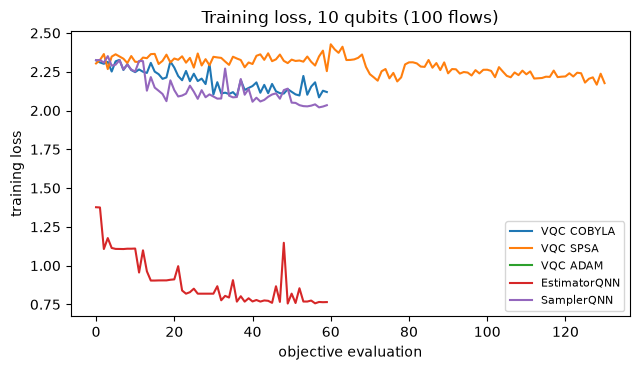

In [18]:
def run_variational(D, b):
    n, seed = D["n"], D["seed"]
    itr, _ = train_test_split(np.arange(len(D["ytr"])), train_size=b["train"], stratify=D["ytr"], random_state=seed)
    ite, _ = train_test_split(np.arange(len(D["yte"])), train_size=b["test"], stratify=D["yte"], random_state=seed)
    Xa, ya, Xb, yb = D["Ptr"][itr], D["ytr"][itr], D["Pte"][ite], D["yte"][ite]
    an = real_amplitudes(n, reps=2, entanglement="full"); sim = BatchedAnsatzSim(an)
    S_tr, S_te = sim.input_states(Xa), sim.input_states(Xb)
    out, hist = {}, {}
    specs = [("VQC COBYLA", "sampler", SHOTS_VQC, COBYLA(maxiter=b["cobyla"])), ("VQC SPSA", "sampler", SHOTS_VQC, SPSA(maxiter=b["spsa"])),
             ("VQC ADAM", "sampler", SHOTS_VQC, ADAM(maxiter=b["adam"], lr=0.1)),            # CHOICE: lr 0.1 because only a few steps are affordable
             ("EstimatorQNN", "estimator", None, COBYLA(maxiter=b["cobyla"])), ("SamplerQNN", "sampler", SHOTS_SAMPLER_QNN, COBYLA(maxiter=b["cobyla"]))]
    for name, kind, shots, opt in specs:
        if name == "VQC ADAM" and b["adam"] == 0:
            continue
        t0 = time.perf_counter(); w, h, fwd = train_qnn(sim, S_tr, ya, kind, shots, opt, seed)
        p = fwd(S_te, w).argmax(1); out[name] = metrics(yb, p, time.perf_counter() - t0); hist[name] = h
        out[name]["train_acc"] = accuracy_score(ya, make_outputs(sim, kind, shots, np.random.default_rng(seed + 1))(S_tr, w).argmax(1))
    for name, mdl in (("RandomForest (same subset)", RandomForestClassifier(n_estimators=100, random_state=seed)), ("SVM RBF (same subset)", SVC(kernel="rbf", C=SVM_C))):
        t0 = time.perf_counter(); mdl.fit(Xa, ya); out[name] = metrics(yb, mdl.predict(Xb), time.perf_counter() - t0)
    fk = FidelityKernel(n, "z"); out["QSVC Z (same subset)"] = metrics(yb, svc_pre(fk.gram(Xa), ya, fk.gram(Xb, Xa)), np.nan)
    return out, hist

VAR, VARHIST = {}, {}
for (n, N), b in VAR_BUDGET.items():
    t0 = time.perf_counter(); VAR[(n, N)], VARHIST[(n, N)] = run_variational(prepare(n, N), b)
    print(f"variational models, {n} qubits, {N:,}-flow configuration: trained on {b['train']} flows, tested on {b['test']} flows, "
          f"COBYLA/SPSA/Adam iterations {b['cobyla']}/{b['spsa']}/{b['adam']} ({time.perf_counter()-t0:.0f} s)", flush=True)
    display(pd.DataFrame(VAR[(n, N)]).T.round(4))
fig, axs = plt.subplots(1, len(VAR_BUDGET), figsize=(6.5 * len(VAR_BUDGET), 3.8), squeeze=False)
for a, (cfg, hh) in zip(axs[0], VARHIST.items()):
    for k, v in hh.items():
        a.plot(v, label=k)
    a.set_xlabel("objective evaluation"); a.set_ylabel("training loss"); a.set_title(f"Training loss, {cfg[0]} qubits ({VAR_BUDGET[cfg]['train']} flows)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. The paper's configurations: Tables I and II re-computed

For each configuration $(n, N)$ the cell below runs the classical models and all quantum kernel models with seed 42 (the paper's seed) and stores the metrics. In the full run it repeats the
quantum kernel models (except Pegasos) and the classical models for two extra seeds on the 10-qubit configurations so that mean $\pm$ std over three random subsets is available. The variational models come from Section 8 (small budget).

In [19]:
RES, PRED, EXTRA = {}, {}, {}
for (n, N) in CONFIGS:
    t0 = time.perf_counter(); D = prepare(n, N)
    rc, pc = run_classical(D); rq, pq_, ex, Kd = run_quantum(D); del Kd
    RES[(n, N, SEED)] = {**rq, **rc}; PRED[(n, N, SEED)] = {**pq_, **pc}; EXTRA[(n, N, SEED)] = ex
    print(f"config {n} qubits x {N:,} flows done in {time.perf_counter()-t0:.0f} s | QVE==QSVC-Z predictions: {ex['QVE_equals_QSVC_Z']} | QWE weights {ex['QWE_weights']}", flush=True)
for s in EXTRA_SEEDS:
    for (n, N) in CONFIGS:
        if n > 10:
            continue                       # extra seeds only for the cheaper 10-qubit configurations (CPU budget); Pegasos is not repeated
        t0 = time.perf_counter(); D = prepare(n, N, s)
        rc, pc = run_classical(D); rq, pq_, ex, Kd = run_quantum(D, pegasos=False); del Kd
        RES[(n, N, s)] = {**rq, **rc}; EXTRA[(n, N, s)] = ex
        print(f"seed {s}, config {n} qubits x {N:,} flows done in {time.perf_counter()-t0:.0f} s", flush=True)

config 10 qubits x 2,000 flows done in 36 s | QVE==QSVC-Z predictions: True | QWE weights [0.4845, 0.5155]


In [20]:
QMODELS = ["QVE", "QWE", "QRF", "QSVC Z", "QSVC ZZ", "QSVC Pauli", "QSVC Pegasos"]
CMODELS = ["RandomForest", "KNN", "GradientBoost", "DecisionTree", "SVM RBF", "SVM Poly", "SVM Linear", "LogisticReg", "NaiveBayes"]
for (n, N) in CONFIGS:
    r = RES[(n, N, SEED)]
    tab = pd.DataFrame({m: r[m] for m in QMODELS + CMODELS + ["RandomForest (all features)"]}).T[["acc", "prec", "rec", "f1", "spec", "mcc", "time"]]
    vr = VAR.get((n, N))
    if vr is not None:
        v = pd.DataFrame({m: vr[m] for m in ["VQC COBYLA", "VQC SPSA", "VQC ADAM", "EstimatorQNN", "SamplerQNN"] if m in vr}).T[["acc", "prec", "rec", "f1", "spec", "mcc", "time"]]
        tab = pd.concat([tab.iloc[:7], v, tab.iloc[7:]])
    vb = VAR_BUDGET.get((n, N)); print(f"\n=== {n} qubits, {N:,} flows (seed {SEED}); variational rows: {vb['train'] if vb else '-'} training flows, {vb['test'] if vb else '-'} test flows; others: full split ===")
    display(tab.round(4))
if EXTRA_SEEDS:
    seeds = [SEED] + EXTRA_SEEDS
    for (n, N) in [c for c in CONFIGS if c[0] == 10]:
        agg = pd.DataFrame({m: {k: f"{np.mean([RES[(n, N, s)][m][k] for s in seeds]):.3f} +- {np.std([RES[(n, N, s)][m][k] for s in seeds]):.3f}" for k in ("acc", "f1", "mcc")}
                            for m in ["QVE", "QWE", "QRF", "QSVC Z", "QSVC ZZ", "RandomForest", "KNN", "SVM RBF"]}).T
        print(f"\nmean +- std over seeds {seeds}: {n} qubits, {N:,} flows"); display(agg)


=== 10 qubits, 2,000 flows (seed 42); variational rows: 100 training flows, 300 test flows; others: full split ===


,acc,prec,rec,f1,spec,mcc,time
QVE,0.8383,0.7981,0.8383,0.7908,0.9350,0.7376,2.7057
QWE,0.8950,0.8903,0.8950,0.8892,0.9614,0.8310,2.7931
QRF,0.7717,0.6887,0.7717,0.7088,0.9045,0.6219,1.6808
QSVC Z,0.8383,0.7981,0.8383,0.7908,0.9350,0.7376,1.5818
QSVC ZZ,0.8967,0.8916,0.8967,0.8908,0.9621,0.8337,1.1240
QSVC Pauli,0.8967,0.8916,0.8967,0.8908,0.9621,0.8337,1.1179
QSVC Pegasos,0.7050,0.5447,0.7050,0.6145,0.8906,0.4928,24.1412
VQC COBYLA,0.5500,0.5142,0.5500,0.5304,0.8537,0.2728,3.9914
VQC SPSA,0.5633,0.5627,0.5633,0.5559,0.8630,0.2918,6.5632
VQC ADAM,0.6167,0.5461,0.6167,0.5756,0.8780,0.3648,15.5739


### 9.1 Confusion matrices (attack classes, headline configuration)

Rows are the true classes, columns the predictions, for the headline configuration; the same test flows for every model.

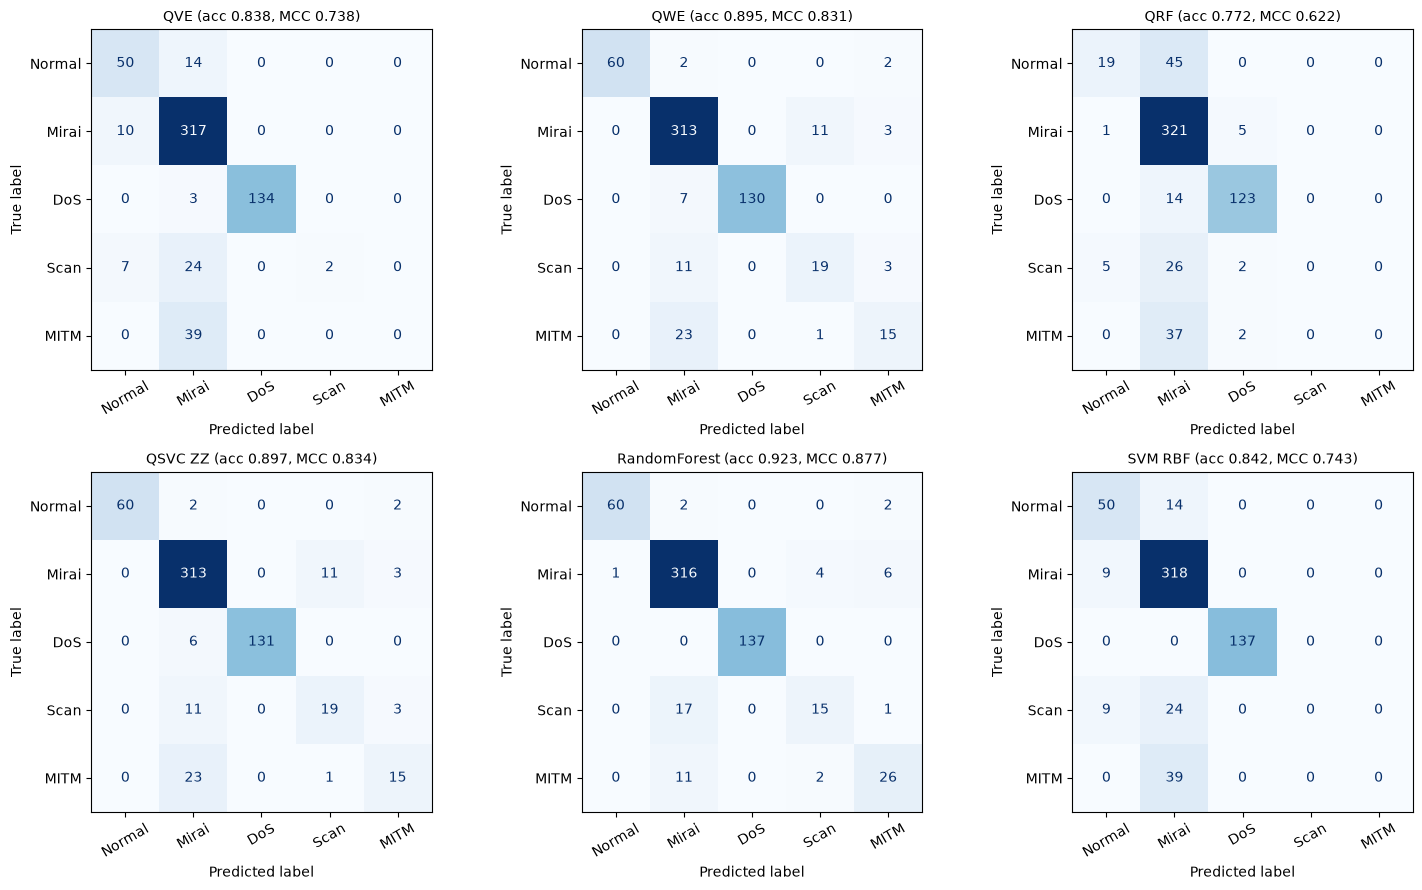

In [21]:
show = ["QVE", "QWE", "QRF", "QSVC ZZ", "RandomForest", "SVM RBF"]
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for a, m in zip(axs.ravel(), show):
    cm = confusion_matrix(Dh["yte"], PRED[(*HEADLINE, SEED)][m], labels=range(5))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=a, colorbar=False, cmap="Blues", values_format="d")
    a.set_title(f"{m} (acc {RES[(*HEADLINE, SEED)][m]['acc']:.3f}, MCC {RES[(*HEADLINE, SEED)][m]['mcc']:.3f})", fontsize=10); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 10. Paper versus this notebook

First the numbers of the paper's Tables I and II (accuracy and MCC) next to ours for every configuration that was run, then one verdict per claim.
The verdict is **reproduced** when our value is within 0.02 of the paper's (two accuracy points; MCC is shown but not used for verdicts), **exceeded** when it is more than 0.02 above,
**not reached** when it is more than 0.02 below. Times are not compared (GPU against CPU, exact vectorised kernel against pair-by-pair circuits). Remember the two largest data differences:
the 79-attribute, de-duplicated mirror (261,538 flows) instead of the 86-attribute original with 625,783 flows; the paper's subsets also appear to be far more imbalanced than a uniform random draw from IoTID20
(its Pegasos baseline, which predicts a single class, scores 91 % accuracy and MCC 0, i.e. one class makes up about 91 % of the paper's test sets; the majority class of the real file, Mirai, is about 66 % of the 625,783 flows and 55 % of the de-duplicated copy used here).

In [22]:
CFG_ORDER = [(10, 5000), (10, 10000), (16, 5000), (16, 10000)]
# paper Tables I and II: model -> {config: (accuracy, MCC)}
def _p(a, b, c, d, ma, mb, mc, md_): return dict(zip(CFG_ORDER, zip((a, b, c, d), (ma, mb, mc, md_))))
PAPER = {
 "QVE": _p(.993, .995, .985, .989, .957, .971, .908, .931), "QWE": _p(.991, .995, .983, .988, .949, .969, .895, .927),
 "QRF": _p(.915, .934, .943, .943, .329, .499, .590, .606),
 "QSVC Z": _p(.988, .994, .988, .992, .925, .965, .923, .949), "QSVC ZZ": _p(.948, .957, .928, .939, .632, .709, .403, .542),
 "QSVC Pauli": _p(.948, .957, .928, .939, .632, .709, .403, .542), "QSVC Pegasos": _p(.910, .909, .913, .912, 0, 0, 0, 0),
 "VQC COBYLA": _p(.879, .902, .657, .659, -.041, -.021, .155, .146), "VQC SPSA": _p(.600, .623, .659, .654, .036, .091, .152, .144),
 "VQC ADAM": _p(.620, .865, .598, .715, .057, -.023, .115, .110), "EstimatorQNN": _p(.858, .871, .894, .851, -.018, .009, .155, .062),
 "SamplerQNN": _p(.608, .804, .594, .508, .131, .090, .061, -.032),
 "RandomForest": _p(.993, .997, .991, .992, .954, .983, .949, .949), "KNN": _p(.990, .996, .989, .991, .936, .975, .937, .943),
 "GradientBoost": _p(.989, .994, .987, .989, .928, .965, .920, .933), "DecisionTree": _p(.985, .992, .985, .986, .904, .956, .916, .918),
 "SVM RBF": _p(.979, .990, .981, .980, .867, .943, .882, .879), "SVM Poly": _p(.977, .986, .980, .979, .849, .917, .878, .870),
 "SVM Linear": _p(.973, .978, .973, .975, .831, .869, .832, .846), "LogisticReg": _p(.969, .971, .972, .972, .804, .836, .831, .832),
 "NaiveBayes": _p(.960, .961, .907, .903, .777, .808, .562, .551)}

def pk(cfg):
    """paper configuration closest to ours (FAST_MODE uses a 2,000-flow sample)"""
    return cfg if cfg in CFG_ORDER else (cfg[0], 5000 if cfg[1] <= 7500 else 10000)

def verdict(ours, paper, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def ours(model, cfg, key="acc"):
    if model in ("VQC COBYLA", "VQC SPSA", "VQC ADAM", "EstimatorQNN", "SamplerQNN"):
        return VAR[cfg][model][key] if (cfg in VAR and model in VAR[cfg]) else np.nan
    return RES[(*cfg, SEED)][model][key]

rows = []
for cfg in CONFIGS:
    for m, d in PAPER.items():
        o_acc, o_mcc = ours(m, cfg), ours(m, cfg, "mcc")
        if np.isnan(o_acc):
            continue
        rows.append(dict(config=f"{cfg[0]}q/{cfg[1]//1000}k", model=m, paper_acc=d[pk(cfg)][0], our_acc=round(o_acc, 3), diff=round(o_acc - d[pk(cfg)][0], 3),
                         paper_mcc=d[pk(cfg)][1], our_mcc=round(o_mcc, 3), verdict=verdict(o_acc, d[pk(cfg)][0])))
CMP = pd.DataFrame(rows)
display(CMP)
print("\nverdict counts per model family (accuracy):")
fam = CMP.assign(family=np.where(CMP.model.isin(["QVE", "QWE", "QRF"]), "ensembles", np.where(CMP.model.str.startswith("QSVC"), "QSVC", np.where(CMP.model.isin(["VQC COBYLA", "VQC SPSA", "VQC ADAM", "EstimatorQNN", "SamplerQNN"]), "variational", "classical"))))
display(pd.crosstab(fam.family, fam.verdict))

,config,model,paper_acc,our_acc,diff,paper_mcc,our_mcc,verdict
0,10q/2k,QVE,0.993,0.838,-0.155,0.957,0.738,not reached
1,10q/2k,QWE,0.991,0.895,-0.096,0.949,0.831,not reached
2,10q/2k,QRF,0.915,0.772,-0.143,0.329,0.622,not reached
3,10q/2k,QSVC Z,0.988,0.838,-0.150,0.925,0.738,not reached
4,10q/2k,QSVC ZZ,0.948,0.897,-0.051,0.632,0.834,not reached
5,10q/2k,QSVC Pauli,0.948,0.897,-0.051,0.632,0.834,not reached
6,10q/2k,QSVC Pegasos,0.910,0.705,-0.205,0.000,0.493,not reached
7,10q/2k,VQC COBYLA,0.879,0.550,-0.329,-0.041,0.273,not reached
8,10q/2k,VQC SPSA,0.600,0.563,-0.037,0.036,0.292,not reached
9,10q/2k,VQC ADAM,0.620,0.617,-0.003,0.057,0.365,reproduced



verdict counts per model family (accuracy):


verdict,not reached,reproduced
family,,
QSVC,4,0
classical,9,0
ensembles,3,0
variational,4,1


In [23]:
def g(model, cfg, key="acc"): return ours(model, cfg, key)
H = HEADLINE
claims = []
def claim(text, paper, ours_txt, verdict_txt): claims.append(dict(claim=text, paper=paper, notebook=ours_txt, verdict=verdict_txt))

claim(f"C1  QVE accuracy / MCC at {H[0]} qubits x {H[1]:,} flows", "0.995 / 0.971", f"{g('QVE', H):.3f} / {g('QVE', H, 'mcc'):.3f}", verdict(g("QVE", H), 0.995))
claim("C2  QWE almost identical to QVE (MCC 0.969 vs 0.971)", "|dMCC| = 0.002", f"|dMCC| = {abs(g('QWE', H, 'mcc') - g('QVE', H, 'mcc')):.3f}; accuracies {g('QWE', H):.3f} / {g('QVE', H):.3f}",
      "reproduced" if abs(g("QWE", H, "mcc") - g("QVE", H, "mcc")) <= 0.02 else "not reached")
gap_rf = g("RandomForest", H) - g("QVE", H)
claim("C3  QVE within 0.2 points of classical Random Forest", "RF - QVE = +0.2 points", f"RF - QVE = {100*gap_rf:+.2f} points", "reproduced" if gap_rf <= 0.022 else "not reached")
gaps = [100 * (g("QVE", c) - g("QRF", c)) for c in CONFIGS]
claim("C4  QVE beats QRF by 4.2 to 7.8 points (over the configurations run)", "4.2 to 7.8 points", "gaps " + ", ".join(f"{x:+.1f}" for x in gaps) + " points",
      "reproduced" if all(2.2 <= x <= 9.8 for x in gaps) else ("exceeded" if min(gaps) > 9.8 else ("not reached" if max(gaps) < 2.2 else "partly: some configurations outside 2.2-9.8 points")))
zr = [verdict(g("QSVC Z", c), PAPER["QSVC Z"][pk(c)][0]) for c in CONFIGS]
claim("C5  QSVC-Z accuracy 98.8 to 99.4 %", "0.988 - 0.994", ", ".join(f"{g('QSVC Z', c):.3f}" for c in CONFIGS), "reproduced" if all(v == "reproduced" for v in zr) else "/".join(sorted(set(zr))))
zz_gap = [100 * (g("QSVC Z", c) - g("QSVC ZZ", c)) for c in CONFIGS]
claim("C6  Z map beats the entangled maps in every configuration (paper: by 3.7 points on average)", "Z > ZZ always; mean 3.7 points",
      "gaps " + ", ".join(f"{x:+.1f}" for x in zz_gap) + f" points; mean {np.mean(zz_gap):+.1f}", "reproduced" if (min(zz_gap) > 0 and abs(np.mean(zz_gap) - 3.7) <= 2.0) else ("direction reproduced, size differs" if min(zz_gap) > 0 else "not reached (Z not always better)"))
if (10, 10000) in CONFIGS and (16, 10000) in CONFIGS:
    d = 100 * (g("QSVC Z", (10, 10000)) - g("QSVC Z", (16, 10000)))
    claim("C7  QSVC-Z loses only 0.2 points from 10 to 16 qubits (10,000 flows)", "-0.2 points", f"{-d:+.2f} points", "reproduced" if abs(d - 0.2) <= 2.0 else "not reached")
else:
    claim("C7  QSVC-Z loses only 0.2 points from 10 to 16 qubits", "-0.2 points", "16-qubit configurations not run (FAST_MODE)", "cannot be checked here")
if VAR:
    vc = list(VAR)[0]
    va = [VAR[vc][m]["acc"] for m in ("VQC COBYLA", "VQC SPSA", "VQC ADAM", "EstimatorQNN", "SamplerQNN") if m in VAR[vc]]
    ksvc = g("QSVC Z", vc if vc in CONFIGS else H)
    claim("C8  Variational models are far behind kernel methods (VQC 60 to 90 %)", "VQC 0.60 - 0.90 vs QSVC-Z 0.99",
          f"variational {min(va):.2f} - {max(va):.2f} (small training subset: {VAR_BUDGET[vc]['train']} flows) vs QSVC-Z {ksvc:.3f}; QSVC-Z on the same {VAR_BUDGET[vc]['train']} flows {VAR[vc]['QSVC Z (same subset)']['acc']:.3f}",
          "reproduced (direction; budgets differ)" if max(va) < ksvc - 0.05 else "not reached")
if (10, 10000) in VAR and (16, 10000) in VAR:
    claim("C9  SamplerQNN collapses from 80.4 to 50.8 % when going from 10 to 16 qubits", "-29.6 points", "run on 5,000-flow configurations only", "cannot be checked here")
else:
    claim("C9  SamplerQNN collapses from 80.4 to 50.8 % from 10 to 16 qubits (barren plateau)", "-29.6 points",
          "variational models were trained on a small subset" + (f"; 10 q: {VAR[(10, 5000)]['SamplerQNN']['acc']:.2f}, 16 q: {VAR[(16, 5000)]['SamplerQNN']['acc']:.2f}" if (10, 5000) in VAR and (16, 5000) in VAR else ""), "cannot be checked (budget differs)")
agree = bool(IMPL.gram_allclose.all() and IMPL.pred_std_eq_pre.all() and IMPL.pred_pre_eq_call.all())
claim("C10 Standard, Precomputed and Callable QSVC give identical results", "nearly identical", f"Gram max diff {IMPL.gram_max_abs_diff.max():.1e}; predictions identical: {agree}", "reproduced" if agree else "not reached")
sp = min(RES[(*c, SEED)][m]["spec"] for c in CONFIGS for m in ("QVE", "QWE", "QSVC Z", "QSVC ZZ", "QRF"))
claim("C11 Specificity 1.00 for all quantum kernel methods (rounded)", "1.00", f"minimum macro specificity {sp:.3f}", "reproduced" if sp >= 0.995 else ("reproduced within 0.02" if sp >= 0.98 else "not reached"))
same = all(EXTRA[(*c, SEED)]["QVE_equals_QSVC_Z"] for c in CONFIGS)
claim("C12 (our check, not a paper claim) QVE should differ from QSVC-Z", "QVE .995 vs QSVC-Z .994 (10q/10k); .993 vs .988 (10q/5k)", f"QVE predictions identical to QSVC-Z in every configuration: {same}", "see Reading the paper critically")
CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 140)
display(CLAIMS)

,claim,paper,notebook,verdict
0,"C1 QVE accuracy / MCC at 10 qubits x 2,000 flows",0.995 / 0.971,0.838 / 0.738,not reached
1,C2 QWE almost identical to QVE (MCC 0.969 vs 0.971),|dMCC| = 0.002,|dMCC| = 0.093; accuracies 0.895 / 0.838,not reached
2,C3 QVE within 0.2 points of classical Random Forest,RF - QVE = +0.2 points,RF - QVE = +8.50 points,not reached
3,C4 QVE beats QRF by 4.2 to 7.8 points (over the configurations run),4.2 to 7.8 points,gaps +6.7 points,reproduced
4,C5 QSVC-Z accuracy 98.8 to 99.4 %,0.988 - 0.994,0.838,not reached
5,C6 Z map beats the entangled maps in every configuration (paper: by 3.7 points on average),Z > ZZ always; mean 3.7 points,gaps -5.8 points; mean -5.8,not reached (Z not always better)
6,C7 QSVC-Z loses only 0.2 points from 10 to 16 qubits,-0.2 points,16-qubit configurations not run (FAST_MODE),cannot be checked here
7,C8 Variational models are far behind kernel methods (VQC 60 to 90 %),VQC 0.60 - 0.90 vs QSVC-Z 0.99,variational 0.55 - 0.62 (small training subset: 100 flows) vs QSVC-Z 0.838; QSVC-Z on the same 100 flows 0.800,reproduced (direction; budgets differ)
8,C9 SamplerQNN collapses from 80.4 to 50.8 % from 10 to 16 qubits (barren plateau),-29.6 points,variational models were trained on a small subset,cannot be checked (budget differs)
9,"C10 Standard, Precomputed and Callable QSVC give identical results",nearly identical,Gram max diff 8.0e-07; predictions identical: True,reproduced


### 10.1 Sensitivity to the preprocessing protocol (fit before the split, as in the paper)

The paper fitted feature selection, scaling and PCA on the whole 5,000 / 10,000-flow sample **before** the 70 : 30 split and reports that fitting on the training part only "produced only minor numerical differences".
This cell repeats the headline configuration with the paper's protocol (transforms fitted on all sampled flows, then split) and compares it with our train-only protocol for the cheap models.

In [24]:
def prepare_leaky(n_qubits, n_flows, seed=SEED):
    """Paper protocol: SelectKBest, MinMax and PCA fitted on the whole sample, then the stratified 70:30 split (the test flows influence the transforms)."""
    sample = pool.sample(n=n_flows, random_state=seed); X = sample[FEATURES].to_numpy(float); y = sample["y"].to_numpy()
    sel = SelectKBest(lambda a, b: mutual_info_classif(a, b, random_state=seed), k=min(2 * n_qubits, X.shape[1])).fit(X, y)
    M = MinMaxScaler((0.0, np.pi)).fit_transform(sel.transform(X)); P = PCA(n_components=n_qubits, random_state=seed).fit_transform(M)
    Ptr, Pte, ytr, yte = train_test_split(P, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    return dict(n=n_qubits, N=n_flows, seed=seed, Ptr=Ptr, Pte=Pte, ytr=ytr, yte=yte)

Dl = prepare_leaky(*HEADLINE)
rl, _, _, Kd = run_quantum(Dl); del Kd
leak = {}
for name, mdl in (("RandomForest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)), ("KNN", KNeighborsClassifier(5)), ("SVM RBF", SVC(kernel="rbf", C=SVM_C))):
    leak[name] = metrics(Dl["yte"], mdl.fit(Dl["Ptr"], Dl["ytr"]).predict(Dl["Pte"]))
leak.update({m: rl[m] for m in ("QVE", "QWE", "QRF", "QSVC Z", "QSVC ZZ")})
rows = []
for m in ("QVE", "QWE", "QRF", "QSVC Z", "QSVC ZZ", "RandomForest", "KNN", "SVM RBF"):
    rows.append(dict(model=m, acc_fit_before_split=leak[m]["acc"], acc_train_only=RES[(*HEADLINE, SEED)][m]["acc"], mcc_fit_before_split=leak[m]["mcc"], mcc_train_only=RES[(*HEADLINE, SEED)][m]["mcc"]))
display(pd.DataFrame(rows).set_index("model").round(4))
print("largest accuracy change from the protocol:", round(max(abs(r["acc_fit_before_split"] - r["acc_train_only"]) for r in rows), 4))

,acc_fit_before_split,acc_train_only,mcc_fit_before_split,mcc_train_only
model,,,,
QVE,0.8367,0.8383,0.7348,0.7376
QWE,0.8933,0.8950,0.8283,0.8310
QRF,0.7733,0.7717,0.6268,0.6219
QSVC Z,0.8367,0.8383,0.7348,0.7376
QSVC ZZ,0.8983,0.8967,0.8365,0.8337
RandomForest,0.9233,0.9233,0.8773,0.8771
KNN,0.8850,0.8850,0.8160,0.8160
SVM RBF,0.8417,0.8417,0.7434,0.7434


largest accuracy change from the protocol: 0.0017


## Reading the paper critically

**QVE cannot beat its own Z member.** Eq. 1 is a hard vote of two classifiers with a rule that sends every disagreement to the Z classifier. If the two members agree the ensemble
returns that common class; if they disagree each class has exactly one vote and the stated tie rule picks the Z member. Hence QVE's prediction is *always* the QSVC-Z prediction when both
members are trained on the same data, and the check in Section 9 (`QVE predictions identical to QSVC-Z`) confirms it for every configuration here. The paper nevertheless reports QVE above QSVC-Z in
every configuration (for example 0.993 against 0.988 accuracy at 10 qubits and 5,000 flows, MCC 0.957 against 0.925), a difference that no vote of this form can produce.
Either the QVE members were trained differently from the stand-alone QSVC-Z (different data subset, a different internal split, a different `C`), or the table entries come from different runs.
The headline "heterogeneous encodings beat homogeneous bagging" is therefore a statement about the Z kernel versus a three-member bootstrap forest on 3 or 4 random PCA components, not about encoding diversity.

**QWE is a model-selection step, not a vote.** With two members, weights proportional to validation accuracy and no tie other than exactly equal weights, the heavier member always wins a disagreement, so QWE's prediction is always that of the member
with the higher validation accuracy (printed in Section 7 as `QWE validation accuracies`). In the paper that member is the Z-map QSVC (hence QWE = QVE = QSVC-Z up to noise); on other data it can be the ZZ / Pauli member.

**QRF is a weak comparator by construction.** With $\lfloor\sqrt n\rfloor$ = 3 (for 10 qubits) or 4 (for 16 qubits) of the PCA features per member, each member sees a third or a quarter of the
information, and the principal components are ordered by variance, so a random subset often drops the leading ones. The 4.2 to 7.8 point advantage of QVE is mostly this feature subsampling, not quantum diversity.

**Z against ZZ depends on the data and on the angle scale.** The PCA scores are used as raw angles, and the ZZ phases $2(\pi-x_i)(\pi-x_j)$ then swing over many multiples of $2\pi$, so the ZZ kernel is close to the identity matrix
(mean off-diagonal value printed in Section 7; a nearly diagonal kernel memorises the training set). The paper finds the Z map 3.7 to 6 points better than ZZ and concludes that "IoT traffic is separable in single-qubit Hilbert space".
In the executed FAST run on this copy of IoTID20 the order is *reversed* (ZZ above Z, see Section 7), so the conclusion is not a property of IoTID20 in general; it depends on the feature selection, the scaling and the missing bandwidth (angle-scale) study.

**Leakage and duplicates.** The paper fitted selection, scaling and PCA before the split (Section 10.1 measures the effect here) and does not mention exact duplicate flows. IoTID20 contains many repeated flows
(the de-duplicated copy used here has 261,538 of the 625,783 flows), and a Random Forest or kernel machine that sees an identical flow in training scores it correctly, so the paper's 99 % may be partly a
duplicate effect that this notebook cannot reproduce on a de-duplicated copy (a plain Random Forest on all attributes of the unique flows reaches only about 0.91 on a 10,000-flow sample).

**Data mismatch.** The paper's Pegasos row (accuracy 0.910, MCC 0.000, weighted precision 0.828 = 0.910 squared) identifies a constant predictor of a class holding 91 % of the test set, whereas Mirai is 66 % of the full file
of the full file. The paper's subsets are therefore much more imbalanced than a uniform random draw; accuracy comparisons with the paper are only indicative.

**Variational baselines are under-trained by design.** The paper's SPSA / Adam / QNN results are at 50 to 90 % after days of GPU time and are used to claim barren plateaus; with a few dozen COBYLA or SPSA steps on random
initial weights a 5-class VQC is simply untrained. The claim that kernel methods beat variational circuits may well hold, but these runs do not distinguish barren plateaus from under-training or from the
shallow Z-map-plus-linear-readout expressivity of `VQC`'s parity-free $x \bmod 5$ read-out.

**Hardware and noise.** Everything is noiseless statevector simulation (the paper says so); no statement about real devices follows.

## Exercises

1. **A genuinely different ensemble.** Train the two QVE members on different bootstrap samples or different feature halves and measure whether the vote beats QSVC-Z. Does the answer depend on `C`?
2. **Kernel bandwidth.** Multiply the PCA angles by a scale $s\in\{0.05, 0.1, 0.25, 0.5, 1\}$ before the ZZ map. Choose $s$ on a validation split of the training data only, and compare with the Z map. Is the paper's "Z beats ZZ" statement still true?
3. **Majority-class world.** Resample the test set so that one class makes up 91 % of it (the paper's apparent regime) and recompute accuracy and MCC for all models. How much of the 99 % is class imbalance?
4. **QRF features.** Replace the random $\lfloor\sqrt n\rfloor$ feature subsets by the leading $\lfloor\sqrt n\rfloor$ principal components. How much of the QVE-QRF gap disappears?
5. **Real circuits.** Replace `FidelityKernel` by `FidelityStatevectorKernel` for 200 training flows at 16 qubits and time both; then run the Z-map kernel with `qiskit_ibm_runtime.fake_provider` noise models to see how
   shallow-circuit robustness (the paper's motivation for the Z map) shows up.